<a href="https://colab.research.google.com/github/isaaccg88/PredictiveMaintenance-AI-Activity4/blob/mejora-academica-actividad4/notebooks/PredictiveMaintenance_Actividad4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 1. Configuración del entorno de ejecución

### Objetivo
Preparar y verificar el entorno de prototipado en Google Colab para la implementación de modelos preentrenados de Hugging Face aplicados al mantenimiento predictivo industrial.

### Procedimiento
Se utiliza Python y la biblioteca PyTorch para identificar las versiones del entorno y comprobar la disponibilidad de aceleración mediante GPU.

La verificación contempla:
- Versión de Python.
- Versión de PyTorch.
- Disponibilidad de CUDA.
- Modelo de GPU asignado por Google Colab.

### Resultado obtenido
- Python: 3.13.15.
- PyTorch: 2.11.0+cu130.
- GPU disponible: Sí.
- Dispositivo: NVIDIA Tesla T4.

### Interpretación técnica
Se confirmó la disponibilidad de aceleración por GPU, necesaria para evaluar modelos fundacionales basados en arquitecturas Transformer.

La configuración es adecuada para comenzar las pruebas de compatibilidad, aunque la capacidad de memoria, la latencia y el consumo de recursos deberán verificarse individualmente para cada modelo.

### Relación con la rúbrica
Contribuye al criterio 2: implementación y prototipado en Google Colab con GPU, documentación del entorno y reproducibilidad.



In [ ]:
import torch
import sys

print("Versión de Python:", sys.version.split()[0])
print("Versión de PyTorch:", torch.__version__)
print("GPU disponible:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU detectada:", torch.cuda.get_device_name(0))
else:
    print("No se detectó GPU.")

Versión de Python: 3.13.15
Versión de PyTorch: 2.11.0+cu130
GPU disponible: True
GPU detectada: Tesla T4


## 2. Adquisición y exploración inicial del dataset

### Objetivo
Obtener un conjunto de datos representativo de condiciones operativas industriales para evaluar modelos preentrenados en una tarea de clasificación binaria de fallas.

### Fuente de información
**Dataset:** AI4I 2020 Predictive Maintenance Dataset  
**Repositorio:** UCI Machine Learning Repository  
**Identificador UCI:** 601  
**Enlace:** https://archive.ics.uci.edu/dataset/601/ai4i+2020+predictive+maintenance+dataset

El dataset contiene datos sintéticos que simulan condiciones de funcionamiento de maquinaria industrial.

### Variables predictoras
1. Type: categoría de producto.
2. Air temperature: temperatura del aire.
3. Process temperature: temperatura del proceso.
4. Rotational speed: velocidad de rotación.
5. Torque: torque aplicado.
6. Tool wear: desgaste de herramienta.

### Variable objetivo
**Machine failure**
- 0: operación sin falla.
- 1: registro con falla.

### Resultados obtenidos
- Registros totales: 10,000.
- Variables predictoras: 6.
- Registros sin falla: 9,661 (96.61%).
- Registros con falla: 339 (3.39%).

### Interpretación
El dataset presenta un desbalance importante entre las clases.

Un clasificador que predijera siempre ausencia de falla alcanzaría 96.61% de accuracy, pero no identificaría ninguna falla.

Por este motivo, se utilizarán precision, recall, F1-score y matrices de confusión, prestando especial atención a la identificación de fallas y a los falsos negativos.

### Limitación del caso de uso
La etiqueta identifica condiciones de falla en los registros disponibles, pero no incorpora un horizonte temporal futuro.

Por tanto, el experimento evalúa la clasificación de estados de falla como componente de una solución de mantenimiento predictivo, sin demostrar todavía anticipación temporal de fallas.

### Relación con la rúbrica
Contribuye a la selección y contextualización del problema, descripción del dataset y fundamentación de las métricas de evaluación.

In [1]:
# Dataset: AI4I 2020 Predictive Maintenance

%pip -q install ucimlrepo

import pandas as pd
from ucimlrepo import fetch_ucirepo

# Descargar el dataset original
dataset = fetch_ucirepo(id=601)

# Separar variables predictoras y objetivo
X = dataset.data.features.copy()
y = dataset.data.targets["Machine failure"].astype(int)

# Construir tabla para exploración
df = X.copy()
df["Machine failure"] = y

print("Dataset cargado correctamente")
print("Total de registros:", len(df))
print("Variables predictoras:", X.shape[1])
print("\nColumnas disponibles:")
print(df.columns.tolist())

print("\nDistribución de fallas (0 = No, 1 = Sí):")
print(y.value_counts().sort_index())

print("\nPrimeros cinco registros:")
display(df.head())


Dataset cargado correctamente
Total de registros: 10000
Variables predictoras: 6

Columnas disponibles:
['Type', 'Air temperature', 'Process temperature', 'Rotational speed', 'Torque', 'Tool wear', 'Machine failure']

Distribución de fallas (0 = No, 1 = Sí):
Machine failure
0    9661
1     339
Name: count, dtype: int64

Primeros cinco registros:


,Type,Air temperature,Process temperature,Rotational speed,Torque,Tool wear,Machine failure
0,M,298.1,308.6,1551,42.8,0,0
1,L,298.2,308.7,1408,46.3,3,0
2,L,298.1,308.5,1498,49.4,5,0
3,L,298.2,308.6,1433,39.5,7,0
4,L,298.2,308.7,1408,40.0,9,0


## 3. Validación de calidad y partición estratificada

### Objetivo
Comprobar la integridad del dataset y establecer un protocolo experimental reproducible para comparar al menos tres modelos preentrenados bajo condiciones equivalentes.

### Validación de calidad
Se revisó la presencia de valores faltantes en todas las variables predictoras y en la variable objetivo.

**Resultado:** no se identificaron valores faltantes.

### Estrategia de partición
Se aplicó una separación estratificada con `random_state=42`:

| Conjunto | Registros | Fallas | % fallas |
|---|---:|---:|---:|
| Entrenamiento | 7,000 | 237 | 3.39% |
| Validación | 1,500 | 51 | 3.40% |
| Prueba | 1,500 | 51 | 3.40% |

### Justificación metodológica
La estratificación conserva la proporción de fallas, lo que resulta especialmente importante debido al desbalance del dataset.

Cada conjunto tiene una finalidad diferenciada:

- **Entrenamiento:** ejemplos etiquetados que utilizarán los modelos para adaptar sus predicciones al problema.
- **Validación:** selección de configuraciones, análisis preliminar y posibles ajustes de umbral.
- **Prueba:** evaluación final del desempeño sobre registros no utilizados en las decisiones de ajuste.

Los tres modelos utilizarán particiones idénticas.

### Control de reproducibilidad
Se utiliza una semilla fija (`SEED=42`) para reproducir la partición.

Las transformaciones que requieran estimar parámetros se ajustarán únicamente con los datos de entrenamiento, evitando fugas de información desde validación y prueba.

### Limitación
La partición es aleatoria y estratificada, adecuada para esta evaluación tabular académica. No representa una validación temporal ni garantiza generalización a maquinaria industrial real.

### Relación con la rúbrica
Contribuye a los criterios 2 y 3: prototipado reproducible, aplicación correcta de métricas y comparación metodológicamente consistente.

Valores faltantes por columna:
Type                   0
Air temperature        0
Process temperature    0
Rotational speed       0
Torque                 0
Tool wear              0
Machine failure        0
dtype: int64

Distribución de las clases:


,count
Machine failure,
Sin falla,9661
Con falla,339



Distribución de los conjuntos:


,Conjunto,Registros,Fallas,Porcentaje de fallas
0,Entrenamiento,7000,237,3.39
1,Validación,1500,51,3.40
2,Prueba,1500,51,3.40


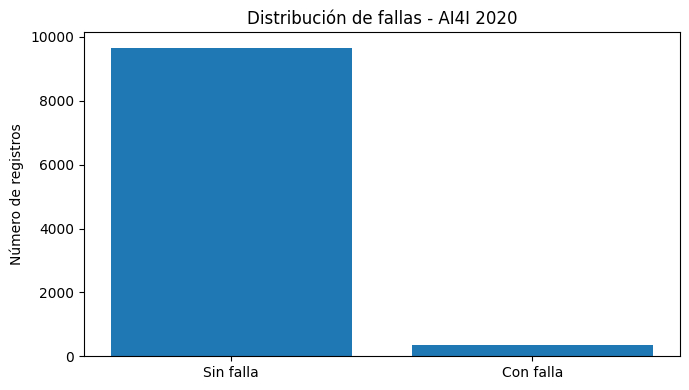

In [2]:
# ACTIVIDAD 4 - ANÁLISIS Y PARTICIÓN DEL DATASET

from sklearn.model_selection import train_test_split
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42

# Revisar calidad inicial
print("Valores faltantes por columna:")
print(df.isnull().sum())

print("\nDistribución de las clases:")
conteo = y.value_counts().sort_index()
display(conteo.rename(index={0: "Sin falla", 1: "Con falla"}))

# División estratificada: 70% / 15% / 15%
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=SEED, stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50,
    random_state=SEED, stratify=y_temp
)

resumen = pd.DataFrame({
    "Conjunto": ["Entrenamiento", "Validación", "Prueba"],
    "Registros": [len(y_train), len(y_val), len(y_test)],
    "Fallas": [int(y_train.sum()), int(y_val.sum()), int(y_test.sum())],
    "Porcentaje de fallas": [
        round(100 * serie.mean(), 2)
        for serie in [y_train, y_val, y_test]
    ]
})

print("\nDistribución de los conjuntos:")
display(resumen)

# Visualización
plt.figure(figsize=(7, 4))
plt.bar(["Sin falla", "Con falla"],
        [conteo.get(0, 0), conteo.get(1, 0)])
plt.title("Distribución de fallas - AI4I 2020")
plt.ylabel("Número de registros")
plt.tight_layout()
plt.show()

## 4. Preparación y codificación de variables predictoras

### Objetivo
Transformar las variables del dataset a una representación numérica consistente, adecuada para la evaluación de modelos fundacionales de clasificación tabular.

### Justificación técnica
El dataset contiene cinco variables numéricas y una variable categórica (`Type`).

Para facilitar una comparación uniforme entre modelos se aplicará codificación One-Hot Encoding a la variable categórica.

Se conservarán las unidades originales de las variables numéricas. Los modelos candidatos podrán aplicar su propio preprocesamiento interno cuando sea necesario.

### Prevención de fuga de información
El codificador se ajustará exclusivamente sobre el conjunto de entrenamiento.

Posteriormente se utilizará la misma transformación para validación y prueba.

La variable objetivo `Machine failure` no formará parte de las características de entrada.

### Resultados esperados
- Representación numérica uniforme.
- Número de características resultantes.
- Verificación de dimensiones.
- Ausencia de valores faltantes después de la transformación.

### Relación con la rúbrica
Implementación reproducible, preparación de datos y establecimiento de condiciones equivalentes para comparar modelos.

In [3]:
# BLOQUE 4 - PREPARACIÓN DE VARIABLES

import numpy as np
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

# Identificar columnas según su tipo
categoricas = ["Type"]
numericas = [col for col in X_train.columns
             if col not in categoricas]

# Configurar el codificador
preprocesador = ColumnTransformer(
    transformers=[
        (
            "categoria",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            categoricas
        ),
        ("numericas", "passthrough", numericas)
    ],
    verbose_feature_names_out=False
)

# Ajustar únicamente con entrenamiento
X_train_array = preprocesador.fit_transform(X_train)

# Aplicar el mismo codificador a validación y prueba
X_val_array = preprocesador.transform(X_val)
X_test_array = preprocesador.transform(X_test)

# Recuperar nombres de variables
nombres_variables = preprocesador.get_feature_names_out()

# Convertir los conjuntos a DataFrames numéricos
def crear_dataframe(array, indice):
    return pd.DataFrame(
        np.asarray(array, dtype=np.float32),
        columns=nombres_variables,
        index=indice
    )

X_train_model = crear_dataframe(
    X_train_array, X_train.index
)
X_val_model = crear_dataframe(
    X_val_array, X_val.index
)
X_test_model = crear_dataframe(
    X_test_array, X_test.index
)

# Verificaciones de calidad
assert X_train_model.isna().sum().sum() == 0
assert X_val_model.isna().sum().sum() == 0
assert X_test_model.isna().sum().sum() == 0

print("PREPROCESAMIENTO COMPLETADO")
print("\nVariables finales:")
print(nombres_variables.tolist())

print("\nDimensiones:")
print("Entrenamiento:", X_train_model.shape)
print("Validación:", X_val_model.shape)
print("Prueba:", X_test_model.shape)

print("\nPrimeros registros transformados:")
display(X_train_model.head())

PREPROCESAMIENTO COMPLETADO

Variables finales:
['Type_H', 'Type_L', 'Type_M', 'Air temperature', 'Process temperature', 'Rotational speed', 'Torque', 'Tool wear']

Dimensiones:
Entrenamiento: (7000, 8)
Validación: (1500, 8)
Prueba: (1500, 8)

Primeros registros transformados:


,Type_H,Type_L,Type_M,Air temperature,Process temperature,Rotational speed,Torque,Tool wear
1888,0.0,0.0,1.0,297.799988,307.399994,1902.0,24.299999,129.0
4858,0.0,1.0,0.0,303.700012,312.299988,1349.0,51.000000,105.0
8990,0.0,1.0,0.0,297.200012,307.899994,1493.0,38.400002,146.0
4901,0.0,0.0,1.0,303.600006,312.299988,1630.0,32.400002,223.0
7957,1.0,0.0,0.0,300.899994,311.899994,2140.0,16.500000,43.0


## 5. Configuración y exploración del ecosistema Hugging Face

### Objetivo
Preparar las dependencias, comprobar la conectividad con Hugging Face Hub e identificar modelos preentrenados compatibles con la clasificación de fallas industriales.

### Componentes del ecosistema

**Models:** repositorio de modelos y checkpoints preentrenados.

**Datasets:** catálogo de conjuntos de datos para investigación, entrenamiento y evaluación.

**Spaces:** aplicaciones y demostraciones interactivas de modelos.

**Hugging Face Hub:** plataforma que integra y distribuye estos recursos.

### Modelos candidatos

| Modelo | Repositorio Hugging Face | Tarea |
|---|---|---|
| TabICLv2 | jingang/TabICL | Clasificación tabular |
| TabPFN v2 | Prior-Labs/TabPFN-v2-clf | Clasificación tabular |
| Mitra | autogluon/mitra-classifier | Clasificación tabular |

Los tres modelos son candidatos preliminares y requieren validación de compatibilidad, disponibilidad, licenciamiento, desempeño y costo computacional.

### Criterios de selección
1. Compatibilidad con clasificación binaria.
2. Disponibilidad de pesos preentrenados.
3. Posibilidad de ejecutar inferencia en Google Colab.
4. Requisitos de memoria y GPU.
5. Licencia y restricciones de utilización.
6. Precisión, recall y F1-score.
7. Latencia y consumo de recursos.
8. Reproducibilidad de la implementación.

### Autenticación
Se utilizará Hugging Face Hub mediante su API.

Cuando sea necesario autenticar, el token se almacenará en los secretos de Google Colab. No se incorporará al código ni a los archivos de GitHub.

### Relación con la rúbrica
Criterio 1: conocimiento del ecosistema Hugging Face y definición justificada de criterios técnicos y prácticos.

Criterio 2: instalación de dependencias, configuración del entorno y autenticación segura.

In [4]:
# BLOQUE 5 - HUGGING FACE HUB

# Instalar dependencias necesarias para el primer modelo
%pip -q install huggingface_hub tabicl

import pandas as pd
import importlib.metadata as metadata
from huggingface_hub import HfApi, login

print("VERSIONES INSTALADAS")
print("huggingface_hub:",
      metadata.version("huggingface_hub"))
print("tabicl:", metadata.version("tabicl"))

# Autenticación opcional mediante secretos de Colab
# Crear un secreto llamado HF_TOKEN si se dispone de él.
try:
    from google.colab import userdata
    token = userdata.get("HF_TOKEN")

    if token:
        login(token=token, add_to_git_credential=False)
        print("\nAutenticación Hugging Face: correcta")
except Exception:
    print("\nAcceso público: no se utilizó un token.")
    print("Los modelos públicos pueden consultarse sin login.")

# Definir los tres candidatos iniciales
candidatos = {
    "TabICLv2": "jingang/TabICL",
    "TabPFN v2": "Prior-Labs/TabPFN-v2-clf",
    "Mitra": "autogluon/mitra-classifier"
}

# Consultar metadatos en Hugging Face
api = HfApi()
catalogo = []

for nombre, repositorio in candidatos.items():
    try:
        info = api.model_info(repositorio)

        licencias = [
            tag.replace("license:", "")
            for tag in info.tags
            if tag.startswith("license:")
        ]

        catalogo.append({
            "Modelo": nombre,
            "Repositorio": info.id,
            "Licencia declarada":
                ", ".join(licencias) if licencias
                else "Verificar",
            "Acceso restringido": str(info.gated),
            "Estado": "Localizado"
        })

    except Exception as error:
        catalogo.append({
            "Modelo": nombre,
            "Repositorio": repositorio,
            "Licencia declarada": "No verificada",
            "Acceso restringido": "No verificado",
            "Estado": type(error).__name__
        })

print("\nCATÁLOGO DE MODELOS CANDIDATOS")
display(pd.DataFrame(catalogo))

print("\nNota: se deberán verificar los términos completos")
print("de cada licencia antes de recomendar producción.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 310.4/310.4 kB 15.0 MB/s eta 0:00:00
VERSIONES INSTALADAS
huggingface_hub: 1.33.0
tabicl: 2.2.0

Acceso público: no se utilizó un token.
Los modelos públicos pueden consultarse sin login.

CATÁLOGO DE MODELOS CANDIDATOS


,Modelo,Repositorio,Licencia declarada,Acceso restringido,Estado
0,TabICLv2,jingang/TabICL,bsd-3-clause,False,Localizado
1,TabPFN v2,Prior-Labs/TabPFN-v2-clf,other,False,Localizado
2,Mitra,autogluon/mitra-classifier,apache-2.0,False,Localizado



Nota: se deberán verificar los términos completos
de cada licencia antes de recomendar producción.


### 5.1. Autenticación segura con Hugging Face Hub

**Objetivo:** demostrar, cuando se disponga de una cuenta, la autenticación con un token **Read** almacenado en *Colab → Secretos* con nombre \`HF_TOKEN\`. El código nunca debe mostrar ni guardar el token en GitHub.

La descarga de modelos públicos **también funciona sin credenciales**. Por ello, la prueba continúa en modo público si no se ha configurado el secreto. Una ejecución no autenticada **no constituye evidencia de autenticación**: para cerrar ese requisito debe mostrarse el mensaje \`AUTENTICADO\` en una ejecución posterior guardada, sin mostrar el token.

**Seguridad:** utilizar un token de solo lectura, permitir acceso del notebook al secreto, no insertar contraseñas en ninguna celda.

In [ ]:
# BLOQUE 5.1 - AUTENTICACIÓN OPCIONAL Y VERIFICABLE
from huggingface_hub import login, whoami
HF_AUTH_STATUS = "PÚBLICO - sin evidencia de autenticación"
try:
    from google.colab import userdata
    token_lectura = userdata.get("HF_TOKEN")
except Exception:
    token_lectura = None
if token_lectura:
    login(token=token_lectura, add_to_git_credential=False)
    identidad_hf = whoami()
    HF_AUTH_STATUS = "AUTENTICADO - token Read mediante secretos"
    print("Hugging Face:", HF_AUTH_STATUS)
    print("Usuario verificado:", identidad_hf.get("name", "no reportado"))
else:
    print("Hugging Face:", HF_AUTH_STATUS)
    print("Configura el secreto HF_TOKEN para acreditar autenticación.")
del token_lectura

## 6. Implementación del modelo preentrenado TabICLv2

### Objetivo
Implementar el primer modelo fundacional preentrenado para clasificación binaria de fallas industriales utilizando la GPU de Google Colab.

### Modelo seleccionado
**Nombre:** TabICLv2  
**Repositorio:** https://huggingface.co/jingang/TabICL  
**Arquitectura:** Transformer para datos tabulares.  
**Paradigma:** In-Context Learning.  
**Licencia declarada:** BSD 3-Clause.

### Justificación
TabICLv2 fue diseñado para resolver problemas de clasificación y regresión sobre datos tabulares.

Su arquitectura resulta pertinente para el dataset AI4I 2020, dado que las variables de entrada son mediciones y características operativas de maquinaria.

El modelo utiliza conocimiento adquirido durante su preentrenamiento y ejemplos etiquetados del problema actual para producir predicciones.

### Configuración experimental
- Clasificación binaria.
- GPU CUDA.
- Semilla aleatoria: 42.
- Cuatro estimadores para la prueba inicial.
- Tamaño de procesamiento de estimadores reducido para limitar memoria.

El uso de cuatro estimadores representa un ajuste inicial de eficiencia. Esta configuración podrá revisarse con los resultados de validación antes de la comparación definitiva.

### Evaluación prevista
Se medirán:
- Accuracy.
- Precision.
- Recall.
- F1-score.
- Matriz de confusión.
- Latencia de inferencia.
- Memoria GPU utilizada.

### Relación con la rúbrica
Implementación funcional de un modelo preentrenado con GPU, decisiones de ajuste mínimo, reproducibilidad y análisis de recursos.

In [5]:
# BLOQUE 6 - CARGA DEL PRIMER MODELO

import time
import torch
from tabicl import TabICLClassifier

# Verificar nuevamente la GPU
if not torch.cuda.is_available():
    raise RuntimeError(
        "Se requiere GPU CUDA. Activa T4 en Colab."
    )

print("GPU:", torch.cuda.get_device_name(0))

# Liberar contadores de memoria para la medición
torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats()

print("\nInicializando TabICLv2...")

inicio_carga = time.perf_counter()

# Modelo fundacional preentrenado
modelo_tabicl = TabICLClassifier(
    device="cuda",
    checkpoint_version="tabicl-classifier-v2-20260212.ckpt",
    n_estimators=4,
    batch_size=2,
    random_state=SEED
)

# Preparación del modelo con los ejemplos etiquetados
# El checkpoint se descarga automáticamente si no está en caché
modelo_tabicl.fit(
    X_train_model,
    y_train.to_numpy()
)

torch.cuda.synchronize()

tiempo_preparacion = (
    time.perf_counter() - inicio_carga
)

memoria_preparacion_mb = (
    torch.cuda.max_memory_allocated() / 1024**2
)

print("\nMODELO PREPARADO CORRECTAMENTE")
print("Modelo: TabICLv2")
print("Registros de entrenamiento:", len(X_train_model))
print("Variables utilizadas:", X_train_model.shape[1])
print("Tiempo inicial de preparación:",
      round(tiempo_preparacion, 2), "segundos")
print("Pico de memoria GPU:",
      round(memoria_preparacion_mb, 2), "MB")


GPU: Tesla T4

Inicializando TabICLv2...
INFO: You are downloading 'tabicl-classifier-v2-20260212.ckpt', the latest best-performing version, used in our TabICLv2 paper.

Checkpoint 'tabicl-classifier-v2-20260212.ckpt' not cached.



tabicl-classifier-v2-20260212.ckpt: reconstructing file:   0%|          |  0.00B /  110MB            

tabicl-classifier-v2-20260212.ckpt: downloading bytes:           |  0.00B            


MODELO PREPARADO CORRECTAMENTE
Modelo: TabICLv2
Registros de entrenamiento: 7000
Variables utilizadas: 8
Tiempo inicial de preparación: 3.35 segundos
Pico de memoria GPU: 108.12 MB


## 7. Evaluación preliminar de TabICLv2

### Objetivo
Medir el desempeño predictivo y la eficiencia computacional del primer modelo preentrenado utilizando exclusivamente el conjunto de validación.

### Métricas de clasificación

**Accuracy:** proporción de predicciones correctas.

**Precision:** proporción de alertas de falla que corresponden a fallas reales.

**Recall:** proporción de fallas reales identificadas correctamente.

**F1-score:** media armónica de precision y recall.

**Balanced accuracy:** promedio del recall de ambas clases.

**Average precision:** indicador complementario del desempeño al ordenar casos según el riesgo estimado de falla.

### Análisis de errores
Se calculará una matriz de confusión para identificar:

- Verdaderos negativos.
- Falsos positivos.
- Falsos negativos.
- Verdaderos positivos.

En el contexto industrial, los falsos negativos representan fallas no detectadas, mientras que los falsos positivos pueden generar inspecciones o intervenciones innecesarias.

### Evaluación computacional
La latencia se medirá después de una inferencia de calentamiento, con el modelo ya cargado.

Se registrará el tiempo total para procesar el conjunto de validación y el promedio amortizado por registro.

Este promedio no representa necesariamente la latencia individual de una predicción en producción.

### Protocolo
Se utilizará inicialmente un umbral de clasificación de 0.50.

Los resultados corresponden a validación; el conjunto de prueba permanecerá reservado para la evaluación final.

### Interpretación esperada
Se analizará si el modelo identifica las fallas sin producir un volumen excesivo de falsas alarmas.

También se examinará si el costo computacional resulta razonable frente a la calidad de las predicciones.

### Relación con la rúbrica
Criterio 3: aplicación correcta de métricas estándar y análisis de precisión frente a eficiencia.

Criterio 4: documentación de resultados y fundamentación de decisiones técnicas.

RESULTADOS DEL MODELO TABICLv2


,Modelo,Conjunto,Accuracy,Precision,Recall,F1-score,Balanced Accuracy,Average Precision,Latencia ms/registro,Memoria GPU MB,Umbral
0,TabICLv2,Validación,0.9853,0.8222,0.7255,0.7708,0.86,0.8728,7.6545,669.646,0.5


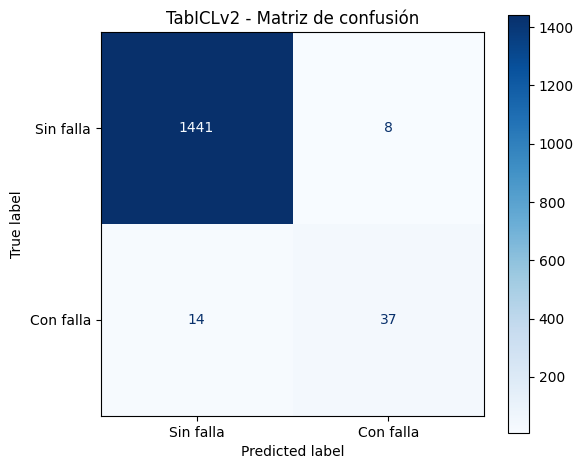


INTERPRETACIÓN OPERATIVA
Fallas detectadas correctamente: 37
Fallas no detectadas: 14
Falsas alarmas: 8
Operaciones normales correctamente clasificadas: 1441

EFICIENCIA
Tiempo total: 11.482 s
Latencia media amortizada: 7.655 ms/registro
Pico de memoria GPU: 669.65 MB


In [6]:
# BLOQUE 7 - EVALUACIÓN DE TABICLv2

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    average_precision_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Inferencia en lotes para controlar memoria
TAMANO_LOTE = 128

def predecir_por_lotes(modelo, datos, tamano_lote=128):
    probabilidades = []

    for inicio in range(0, len(datos), tamano_lote):
        lote = datos.iloc[inicio:inicio + tamano_lote]
        resultado = modelo.predict_proba(lote)
        probabilidades.append(resultado[:, 1])

    return np.concatenate(probabilidades)

# Calentamiento de la GPU/modelo
_ = modelo_tabicl.predict_proba(X_val_model.iloc[:8])
torch.cuda.synchronize()

# Reiniciar medición de memoria
torch.cuda.reset_peak_memory_stats()

# Medir exclusivamente inferencia
inicio = time.perf_counter()

prob_falla = predecir_por_lotes(
    modelo_tabicl,
    X_val_model,
    TAMANO_LOTE
)

torch.cuda.synchronize()
tiempo_inferencia = time.perf_counter() - inicio

# Clasificar con umbral inicial 0.50
umbral = 0.50
predicciones = (prob_falla >= umbral).astype(int)

# Métricas
accuracy = accuracy_score(y_val, predicciones)
precision = precision_score(
    y_val, predicciones, zero_division=0
)
recall = recall_score(
    y_val, predicciones, zero_division=0
)
f1 = f1_score(
    y_val, predicciones, zero_division=0
)
balanced_accuracy = balanced_accuracy_score(
    y_val, predicciones
)
avg_precision = average_precision_score(
    y_val, prob_falla
)

latencia_ms = (
    tiempo_inferencia / len(X_val_model) * 1000
)

memoria_gpu_mb = (
    torch.cuda.max_memory_allocated() / 1024**2
)

# Guardar resultados para la comparación posterior
resultado_tabicl = {
    "Modelo": "TabICLv2",
    "Conjunto": "Validación",
    "Accuracy": accuracy,
    "Precision": precision,
    "Recall": recall,
    "F1-score": f1,
    "Balanced Accuracy": balanced_accuracy,
    "Average Precision": avg_precision,
    "Latencia ms/registro": latencia_ms,
    "Memoria GPU MB": memoria_gpu_mb,
    "Umbral": umbral
}

resultados_validacion = pd.DataFrame(
    [resultado_tabicl]
)

print("RESULTADOS DEL MODELO TABICLv2")
display(resultados_validacion.round(4))

# Matriz de confusión
matriz = confusion_matrix(
    y_val, predicciones, labels=[0, 1]
)

fig, ax = plt.subplots(figsize=(6, 5))

ConfusionMatrixDisplay(
    confusion_matrix=matriz,
    display_labels=["Sin falla", "Con falla"]
).plot(ax=ax, cmap="Blues", values_format="d")

ax.set_title("TabICLv2 - Matriz de confusión")
plt.tight_layout()
plt.show()

# Interpretación operativa
tn, fp, fn, tp = matriz.ravel()

print("\nINTERPRETACIÓN OPERATIVA")
print("Fallas detectadas correctamente:", tp)
print("Fallas no detectadas:", fn)
print("Falsas alarmas:", fp)
print("Operaciones normales correctamente clasificadas:", tn)

print("\nEFICIENCIA")
print("Tiempo total:", round(tiempo_inferencia, 3), "s")
print("Latencia media amortizada:",
      round(latencia_ms, 3), "ms/registro")
print("Pico de memoria GPU:",
      round(memoria_gpu_mb, 2), "MB")


## 8. Implementación del segundo modelo preentrenado: TabPFN v2

### Objetivo
Implementar un segundo modelo fundacional de clasificación tabular para evaluar su capacidad de identificar fallas industriales y comparar su desempeño con TabICLv2.

### Identificación del modelo

- **Nombre:** TabPFN v2.
- **Desarrollador:** Prior Labs.
- **Repositorio:** https://huggingface.co/Prior-Labs/TabPFN-v2-clf
- **Arquitectura:** Transformer para datos tabulares.
- **Tarea:** clasificación binaria.
- **Licencia:** Prior Labs License 1.1, con requisitos de atribución adicionales.

### Justificación de selección
TabPFN utiliza patrones adquiridos durante su preentrenamiento para resolver tareas de clasificación mediante ejemplos etiquetados.

Se selecciona porque permite comparar una segunda arquitectura fundacional con TabICLv2 utilizando el mismo dataset industrial.

### Configuración experimental
- Conjunto de entrenamiento: 7,000 registros.
- Variables predictoras: 8 después de la codificación.
- Conjunto de validación: 1,500 registros.
- GPU: NVIDIA Tesla T4.
- Número de estimadores: 4.
- Semilla aleatoria: 42.
- Checkpoint: versión v2 explícita.

### Control experimental
Se mantienen los mismos registros, variables y umbral inicial de decisión utilizados en TabICLv2.

Los resultados podrán diferir por la arquitectura y los mecanismos internos de preprocesamiento e inferencia.

Se registrarán por separado:
1. Tiempo de preparación y carga.
2. Tiempo de inferencia.
3. Memoria GPU.
4. Métricas de clasificación.

### Relación con la rúbrica
Contribuye a los criterios 1 y 2 mediante la selección justificada y la implementación reproducible de un segundo modelo preentrenado.

In [7]:
# BLOQUE 8 - INSTALACIÓN Y PREPARACIÓN DE TABPFN V2

%pip -q install tabpfn

import gc
import time
import torch
import importlib.metadata as metadata

from tabpfn import TabPFNClassifier
from tabpfn.constants import ModelVersion

# Verificar requisitos
assert torch.cuda.is_available(), "Se requiere GPU CUDA."
assert X_train_model.shape == (7000, 8)

print("MODELO 2: TABPFN V2")
print("Biblioteca TabPFN:", metadata.version("tabpfn"))
print("GPU:", torch.cuda.get_device_name(0))

# Liberar el primer modelo de la memoria GPU.
# Sus métricas permanecen en resultados_validacion.
if "modelo_tabicl" in globals():
    del modelo_tabicl

gc.collect()
torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats()

# Cargar explícitamente la versión 2 del modelo
inicio_carga_tabpfn = time.perf_counter()

modelo_tabpfn = TabPFNClassifier.create_default_for_version(
    ModelVersion.V2,
    device="cuda",
    n_estimators=4,
    random_state=SEED,
    fit_mode="low_memory"
)

# Preparar modelo con los mismos datos de entrenamiento
modelo_tabpfn.fit(
    X_train_model,
    y_train.to_numpy()
)

torch.cuda.synchronize()

tiempo_preparacion_tabpfn = (
    time.perf_counter() - inicio_carga_tabpfn
)

memoria_preparacion_tabpfn = (
    torch.cuda.max_memory_allocated() / 1024**2
)

print("\nTABPFN V2 PREPARADO")
print("Registros:", len(X_train_model))
print("Variables:", X_train_model.shape[1])
print("Checkpoint:", modelo_tabpfn.model_path)
print("Tiempo de preparación:",
      round(tiempo_preparacion_tabpfn, 2), "s")
print("Pico de memoria GPU:",
      round(memoria_preparacion_tabpfn, 2), "MB")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 850.0/850.0 kB 29.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.4/80.4 kB 8.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 595.9/595.9 kB 50.6 MB/s eta 0:00:00
MODELO 2: TABPFN V2
Biblioteca TabPFN: 9.2.0
GPU: Tesla T4


tabpfn-v2-classifier-finetuned-zk73skhh.(…): reconstructing file:   0%|          |  0.00B / 29.0MB            

tabpfn-v2-classifier-finetuned-zk73skhh.(…): downloading bytes:           |  0.00B            

config.json:   0%|          | 0.00/37.0 [00:00<?, ?B/s]


TABPFN V2 PREPARADO
Registros: 7000
Variables: 8
Checkpoint: /root/.cache/tabpfn/tabpfn-v2-classifier-finetuned-zk73skhh.ckpt
Tiempo de preparación: 1.32 s
Pico de memoria GPU: 36.76 MB


## 9. Evaluación de TabPFN v2 y comparación preliminar

### Objetivo
Medir el desempeño predictivo y computacional del segundo modelo preentrenado, siguiendo el mismo protocolo experimental aplicado a TabICLv2.

### Metodología de evaluación
Se utilizará el conjunto de validación de 1,500 registros, que incluye 51 fallas reales.

Las predicciones se realizarán mediante inferencia por lotes, utilizando las probabilidades de la clase positiva.

El umbral inicial será de 0.50.

### Métricas
- Accuracy.
- Precision.
- Recall.
- F1-score.
- Balanced accuracy.
- Average precision.
- Matriz de confusión.
- Latencia media amortizada por registro.
- Pico de memoria GPU.

### Comparación con TabICLv2
Se generará una tabla que permita comparar los resultados de ambos modelos bajo las mismas particiones de datos.

Se analizarán especialmente:

1. Diferencias en la detección de fallas reales.
2. Reducción o aumento de falsos negativos.
3. Número de falsas alarmas.
4. Diferencias en el F1-score.
5. Costo computacional de la inferencia.

### Criterio de interpretación
Un accuracy más elevado no implica necesariamente una solución superior para mantenimiento industrial.

El análisis considerará prioritariamente el recall y el F1-score de la clase de falla, junto con las consecuencias operativas de los errores y el consumo de recursos.

### Alcance
Esta evaluación es preliminar y utiliza únicamente datos de validación. La elección definitiva se realizará después de evaluar tres modelos y comparar sus resultados sobre el conjunto de prueba reservado.

### Relación con la rúbrica
Contribuye a los criterios 3 y 4 mediante métricas estándar, comparación objetiva, análisis de eficiencia y justificación técnica.

COMPARACIÓN PRELIMINAR DE MODELOS


,Modelo,Conjunto,Accuracy,Precision,Recall,F1-score,Balanced Accuracy,Average Precision,Latencia ms/registro,Memoria GPU MB,Umbral
0,TabICLv2,Validación,0.9853,0.8222,0.7255,0.7708,0.8600,0.8728,7.6545,669.6460,0.5
1,TabPFN v2,Validación,0.9867,0.8780,0.7059,0.7826,0.8512,0.8466,22.1738,296.3408,0.5


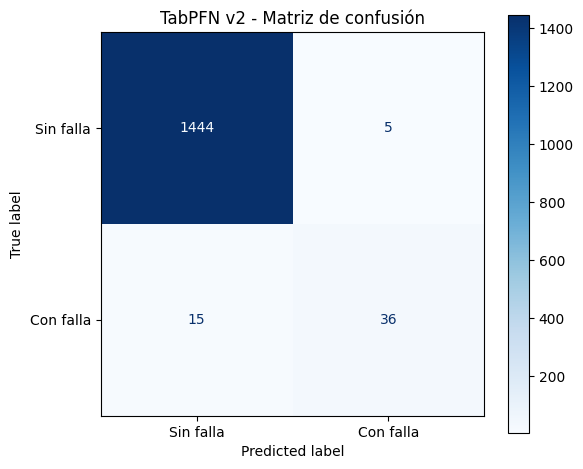


INTERPRETACIÓN OPERATIVA
Fallas detectadas: 36
Fallas no detectadas: 15
Falsas alarmas: 5
Operaciones normales detectadas: 1444

EFICIENCIA
Tiempo total: 33.261 s
Latencia media amortizada: 22.174 ms/registro
Pico de memoria GPU: 296.34 MB


In [8]:
# BLOQUE 9 - EVALUACIÓN DE TABPFN V2

# Utilizamos los imports y las métricas del bloque 7.

TAMANO_LOTE_TABPFN = 128

def predecir_tabpfn_por_lotes(modelo, datos, tamano=128):
    probabilidades = []

    for inicio in range(0, len(datos), tamano):
        lote = datos.iloc[inicio:inicio + tamano]
        resultado = modelo.predict_proba(lote)
        probabilidades.append(resultado[:, 1])

    return np.concatenate(probabilidades)

# Calentamiento antes de medir latencia
_ = modelo_tabpfn.predict_proba(X_val_model.iloc[:8])
torch.cuda.synchronize()

# Medición de inferencia
torch.cuda.reset_peak_memory_stats()
inicio = time.perf_counter()

prob_tabpfn = predecir_tabpfn_por_lotes(
    modelo_tabpfn,
    X_val_model,
    TAMANO_LOTE_TABPFN
)

torch.cuda.synchronize()
tiempo_tabpfn = time.perf_counter() - inicio

# Predicción binaria con umbral 0.50
pred_tabpfn = (prob_tabpfn >= 0.50).astype(int)

# Métricas de desempeño
resultado_tabpfn = {
    "Modelo": "TabPFN v2",
    "Conjunto": "Validación",
    "Accuracy": accuracy_score(y_val, pred_tabpfn),
    "Precision": precision_score(
        y_val, pred_tabpfn, zero_division=0
    ),
    "Recall": recall_score(
        y_val, pred_tabpfn, zero_division=0
    ),
    "F1-score": f1_score(
        y_val, pred_tabpfn, zero_division=0
    ),
    "Balanced Accuracy": balanced_accuracy_score(
        y_val, pred_tabpfn
    ),
    "Average Precision": average_precision_score(
        y_val, prob_tabpfn
    ),
    "Latencia ms/registro":
        tiempo_tabpfn / len(X_val_model) * 1000,
    "Memoria GPU MB":
        torch.cuda.max_memory_allocated() / 1024**2,
    "Umbral": 0.50
}

# Agregar a la tabla creada en el bloque 7
resultados_validacion = pd.concat(
    [
        resultados_validacion[
            resultados_validacion["Modelo"] != "TabPFN v2"
        ],
        pd.DataFrame([resultado_tabpfn])
    ],
    ignore_index=True
)

print("COMPARACIÓN PRELIMINAR DE MODELOS")
display(resultados_validacion.round(4))

# Matriz de confusión
matriz_tabpfn = confusion_matrix(
    y_val, pred_tabpfn, labels=[0, 1]
)

fig, ax = plt.subplots(figsize=(6, 5))

ConfusionMatrixDisplay(
    confusion_matrix=matriz_tabpfn,
    display_labels=["Sin falla", "Con falla"]
).plot(
    ax=ax,
    cmap="Blues",
    values_format="d"
)

ax.set_title("TabPFN v2 - Matriz de confusión")
plt.tight_layout()
plt.show()

# Interpretación operativa
tn, fp, fn, tp = matriz_tabpfn.ravel()

print("\nINTERPRETACIÓN OPERATIVA")
print("Fallas detectadas:", tp)
print("Fallas no detectadas:", fn)
print("Falsas alarmas:", fp)
print("Operaciones normales detectadas:", tn)

print("\nEFICIENCIA")
print("Tiempo total:", round(tiempo_tabpfn, 3), "s")
print(
    "Latencia media amortizada:",
    round(resultado_tabpfn["Latencia ms/registro"], 3),
    "ms/registro"
)
print(
    "Pico de memoria GPU:",
    round(resultado_tabpfn["Memoria GPU MB"], 2),
    "MB"
)


## 10. Implementación del tercer modelo preentrenado: Mitra

### Objetivo
Implementar y evaluar Mitra, un modelo fundacional de clasificación tabular, como tercer candidato para detectar condiciones de falla en maquinaria industrial.

### Identificación del modelo

- **Nombre:** Mitra Classifier (v1).
- **Desarrollador:** AutoGluon / Amazon.
- **Repositorio:** https://huggingface.co/autogluon/mitra-classifier
- **Arquitectura:** Transformer bidimensional para datos tabulares.
- **Parámetros:** aproximadamente 75.7 millones.
- **Paradigma:** In-Context Learning.
- **Licencia:** Apache 2.0.
- **Biblioteca:** AutoGluon Tabular.

### Justificación de selección
Mitra fue preentrenado mediante conjuntos de datos sintéticos con estructuras estadísticas diversas.

Su objetivo es transferir los patrones aprendidos a nuevos problemas tabulares mediante ejemplos etiquetados.

Resulta pertinente para el caso de uso, dado que AI4I 2020 contiene variables de sensores y condiciones operativas representadas mediante datos tabulares.

### Configuración experimental
- Entradas: ocho características numéricas codificadas.
- Datos disponibles para entrenamiento: 7,000 registros.
- Validación externa: 1,500 registros.
- GPU: NVIDIA Tesla T4.
- Modelo preentrenado Mitra v1.
- Fine-tuning: desactivado.
- Estimadores: 1.
- Ensambles adicionales: desactivados.
- Separación interna para AutoGluon: 5%.

### Consideraciones metodológicas
La API de AutoGluon realiza una partición interna de los datos de entrenamiento para su propio proceso de validación.

Por ello, Mitra no utilizará exactamente el mismo número efectivo de ejemplos de contexto que TabICLv2 y TabPFN v2.

Esta diferencia deberá reportarse como limitación de comparabilidad. Asimismo, los modelos utilizan distintos números de estimadores por restricciones de eficiencia.

### Evaluación de recursos
Se registrarán el tiempo de preparación, la memoria GPU observada y la capacidad de ejecución en Colab.

### Relación con la rúbrica
Criterios 1 y 2: evaluación contextualizada de un tercer modelo preentrenado, configuración del entorno, implementación reproducible y justificación técnica.



In [9]:
# BLOQUE 10 - INSTALACIÓN E IMPLEMENTACIÓN DE MITRA V1

# Versión de AutoGluon compatible con Python 3.13
%pip -q install "autogluon.tabular[mitra]==1.6.1"

import gc
import time
import random
import numpy as np
import pandas as pd
import torch
import importlib.metadata as metadata

from autogluon.tabular import TabularDataset, TabularPredictor

# Verificaciones iniciales
assert torch.cuda.is_available(), "Se requiere GPU CUDA."
assert X_train_model.shape == (7000, 8)

print("MODELO 3: MITRA V1")
print("AutoGluon Tabular:",
      metadata.version("autogluon.tabular"))
print("GPU:", torch.cuda.get_device_name(0))

# Establecer semillas
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# Liberar referencia del segundo modelo
if "modelo_tabpfn" in globals():
    del modelo_tabpfn

gc.collect()
torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats()

# Construir dataset compatible con AutoGluon
# Se preservan las mismas ocho variables.
datos_mitra = X_train_model.reset_index(drop=True).copy()
datos_mitra["Machine failure"] = (
    y_train.reset_index(drop=True).astype(int)
)

train_mitra = TabularDataset(datos_mitra)

print("\nDataset Mitra:", train_mitra.shape)
print("Fallas:", int(train_mitra["Machine failure"].sum()))

# Ruta temporal del modelo dentro de Colab
ruta_mitra = "/content/AutoGluonModels/mitra_actividad4"

# Crear predictor
mitra_predictor = TabularPredictor(
    label="Machine failure",
    problem_type="binary",
    eval_metric="roc_auc",
    path=ruta_mitra
)

print("\nPreparando Mitra...")

inicio_mitra = time.perf_counter()

# Únicamente Mitra v1.
# No se entrenarán algoritmos adicionales de AutoGluon.
mitra_predictor.fit(
    train_data=train_mitra,
    hyperparameters={
        "MITRA": {
            "hf_model": "autogluon/mitra-classifier",
            "fine_tune": False,
            "n_estimators": 1
        }
    },
    holdout_frac=0.05,
    num_bag_folds=0,
    num_gpus=1,
    fit_weighted_ensemble=False,
    verbosity=2
)

torch.cuda.synchronize()

tiempo_preparacion_mitra = (
    time.perf_counter() - inicio_mitra
)

memoria_preparacion_mitra = (
    torch.cuda.max_memory_allocated() / 1024**2
)

print("\nMITRA PREPARADO CORRECTAMENTE")
print("Modelo Hugging Face: autogluon/mitra-classifier")
print("Modelos entrenados por AutoGluon:",
      mitra_predictor.model_names())
print("Tiempo de preparación:",
      round(tiempo_preparacion_mitra, 2), "s")
print("Pico observado de memoria CUDA:",
      round(memoria_preparacion_mitra, 2), "MB")


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 514.8/514.8 kB 25.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 248.4/248.4 kB 27.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 112.3/112.3 kB 13.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 90.7/90.7 kB 11.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 163.8/163.8 kB 18.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.6/61.6 kB 7.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 140.0/140.0 kB 16.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.1/16.1 MB 100.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 90.2/90.2 kB 10.5 MB/s eta 0:00:00
MODELO 3: MITRA V1
AutoGluon Tabular: 1.6.1
GPU: Tesla T4


Verbosity: 2 (Standard Logging)
=================== System Info ===================
AutoGluon Version:  1.6.1
Python Version:     3.13.15
Operating System:   Linux
Platform Machine:   x86_64
Platform Version:   #1 SMP Thu Apr 30 18:17:14 UTC 2026
CPU Count:          2
Pytorch Version:    2.11.0+cu130
CUDA Version:       13.0
GPU Memory:         GPU 0: 14.55/14.56 GB
Total GPU Memory:   Free: 14.55 GB, Allocated: 0.01 GB, Total: 14.56 GB
GPU Count:          1
Memory Avail:       10.32 GB / 12.67 GB (81.5%)
Disk Space Avail:   70.04 GB / 112.64 GB (62.2%)
No presets specified! To achieve strong results with AutoGluon, it is recommended to use the available presets. Defaulting to `'medium'`...
	Recommended Presets (For more details refer to https://auto.gluon.ai/stable/tutorials/tabular/tabular-essentials.html#presets):
	presets='extreme'  : Use this if you have a GPU. The go-to preset for best results, and the one to use for benchmark comparisons. New in v1.6: far better than 'best' on d


Dataset Mitra: (7000, 9)
Fallas: 237

Preparando Mitra...


Beginning AutoGluon training ...
AutoGluon will save models to "/content/AutoGluonModels/mitra_actividad4"
Train Data Rows:    7000
Train Data Columns: 8
Label Column:       Machine failure
Problem Type:       binary
Preprocessing data...
Selected class <--> label mapping:  class 1 = 1, class 0 = 0
Using Feature Generators to preprocess the data ...
Fitting AutoMLPipelineFeatureGenerator...
	Available Memory:                    10570.85 MB
	Train Data (Original)  Memory Usage: 0.21 MB (0.0% of available memory)
	Inferring data type of each feature based on column values. Set feature_metadata_in to manually specify special dtypes of the features.
	Stage 1 Generators:
		Fitting AsTypeFeatureGenerator...
			Note: Converting 3 features to boolean dtype as they only contain 2 unique values.
	Stage 2 Generators:
		Fitting FillNaFeatureGenerator...
	Stage 3 Generators:
		Fitting IdentityFeatureGenerator...
	Stage 4 Generators:
		Fitting DropUniqueFeatureGenerator...
	Stage 5 Generators:
		Fit

config.json:   0%|          | 0.00/86.0 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  303MB            

model.safetensors: downloading bytes:           |  0.00B            

Reducing max_samples_support from 8192to 4096 due to OOM error.


	0.9316	 = Validation score   (roc_auc)
	24.96s	 = Training   runtime
	4.61s	 = Validation runtime
AutoGluon training complete, total runtime = 31.04s ... Best model: Mitra | Estimated inference throughput: 75.9 rows/s (350 batch size)
TabularPredictor saved. To load, use: predictor = TabularPredictor.load("/content/AutoGluonModels/mitra_actividad4")



MITRA PREPARADO CORRECTAMENTE
Modelo Hugging Face: autogluon/mitra-classifier
Modelos entrenados por AutoGluon: ['Mitra']
Tiempo de preparación: 32.26 s
Pico observado de memoria CUDA: 13404.98 MB


## 11. Evaluación de Mitra y comparación de los tres modelos

### Objetivo
Evaluar el desempeño de Mitra utilizando los mismos 1,500 registros de validación empleados anteriormente y construir una tabla comparativa de los tres modelos preentrenados.

### Metodología
Se obtendrán probabilidades de la clase positiva (Machine failure = 1).

Se aplicará inicialmente un umbral de decisión de 0.50.

La inferencia se realizará por lotes y se medirá su tiempo después de ejecutar un calentamiento del modelo.

### Métricas de desempeño
1. Accuracy.
2. Precision.
3. Recall.
4. F1-score.
5. Balanced accuracy.
6. Average precision.
7. Matriz de confusión.

### Eficiencia computacional
Se calcularán:
- Tiempo total de inferencia.
- Latencia media amortizada por registro.
- Pico de memoria GPU observado.

La latencia obtenida corresponde a procesamiento por lotes, no a inferencia individual de producción.

La medición de memoria CUDA puede no reflejar completamente el consumo de AutoGluon en procesos adicionales.

### Análisis comparativo
Se integrarán los resultados de:
- TabICLv2.
- TabPFN v2.
- Mitra v1.

La comparación contemplará calidad predictiva, falsos negativos, falsas alarmas, latencia y recursos utilizados.

### Interpretación de negocio
Un modelo con mayor accuracy no será necesariamente el más adecuado.

Se considerarán especialmente el recall, el F1-score y el equilibrio entre errores de clasificación y eficiencia computacional.

### Limitaciones
Los modelos utilizan mecanismos internos distintos y configuraciones iniciales diferentes.

Por tanto, la comparación representa una evaluación práctica de las configuraciones ensayadas, no un experimento aislado exclusivamente sobre las arquitecturas.

Los resultados seguirán siendo preliminares hasta su evaluación final sobre el conjunto de prueba reservado.

### Relación con la rúbrica
Criterio 3: aplicación de métricas estándar y comparación del desempeño.

Criterio 4: documentación estructurada y fundamentación de las decisiones técnicas.

COMPARACIÓN DE TRES MODELOS PREENTRENADOS


,Modelo,Conjunto,Accuracy,Precision,Recall,F1-score,Balanced Accuracy,Average Precision,Latencia ms/registro,Memoria GPU MB,Umbral
0,TabICLv2,Validación,0.9853,0.8222,0.7255,0.7708,0.8600,0.8728,7.6545,669.6460,0.5
1,TabPFN v2,Validación,0.9867,0.8780,0.7059,0.7826,0.8512,0.8466,22.1738,296.3408,0.5
2,Mitra v1,Validación,0.9787,0.8519,0.4510,0.5897,0.7241,0.7049,38.5543,6209.1641,0.5


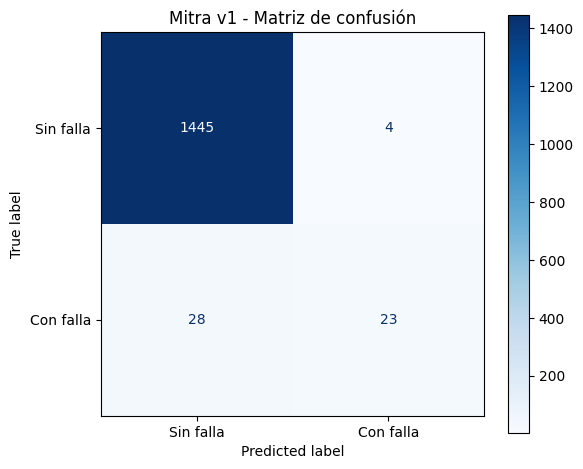


INTERPRETACIÓN OPERATIVA
Fallas detectadas: 23
Fallas no detectadas: 28
Falsas alarmas: 4
Operaciones normales detectadas: 1445

EFICIENCIA
Tiempo total: 57.832 s
Latencia media amortizada: 38.554 ms/registro
Pico observado de memoria CUDA: 6209.16 MB


In [10]:
# BLOQUE 11 - EVALUACIÓN DE MITRA V1

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Validar que se ejecutó correctamente el bloque 10
assert mitra_predictor.is_fit, "Mitra no está preparado."

TAMANO_LOTE_MITRA = 128

def predecir_mitra_por_lotes(predictor, datos, tamano=128):
    probabilidades = []

    for inicio in range(0, len(datos), tamano):
        lote = datos.iloc[inicio:inicio + tamano]

        resultado = predictor.predict_proba(lote)

        # Seleccionar explícitamente la clase positiva
        if 1 not in resultado.columns:
            raise ValueError(
                "No se encontró la clase positiva 1."
            )

        probabilidades.append(
            resultado[1].to_numpy()
        )

    return np.concatenate(probabilidades)

# Calentamiento
_ = mitra_predictor.predict_proba(
    X_val_model.iloc[:8]
)

torch.cuda.synchronize()
torch.cuda.reset_peak_memory_stats()

# Medición de inferencia
inicio = time.perf_counter()

prob_mitra = predecir_mitra_por_lotes(
    mitra_predictor,
    X_val_model,
    TAMANO_LOTE_MITRA
)

torch.cuda.synchronize()
tiempo_mitra = time.perf_counter() - inicio

# Umbral inicial
pred_mitra = (prob_mitra >= 0.50).astype(int)

# Métricas
resultado_mitra = {
    "Modelo": "Mitra v1",
    "Conjunto": "Validación",
    "Accuracy": accuracy_score(y_val, pred_mitra),
    "Precision": precision_score(
        y_val, pred_mitra, zero_division=0
    ),
    "Recall": recall_score(
        y_val, pred_mitra, zero_division=0
    ),
    "F1-score": f1_score(
        y_val, pred_mitra, zero_division=0
    ),
    "Balanced Accuracy": balanced_accuracy_score(
        y_val, pred_mitra
    ),
    "Average Precision": average_precision_score(
        y_val, prob_mitra
    ),
    "Latencia ms/registro":
        tiempo_mitra / len(X_val_model) * 1000,
    "Memoria GPU MB":
        torch.cuda.max_memory_allocated() / 1024**2,
    "Umbral": 0.50
}

# Actualizar tabla comparativa
resultados_validacion = pd.concat(
    [
        resultados_validacion[
            resultados_validacion["Modelo"] != "Mitra v1"
        ],
        pd.DataFrame([resultado_mitra])
    ],
    ignore_index=True
)

print("COMPARACIÓN DE TRES MODELOS PREENTRENADOS")
display(resultados_validacion.round(4))

# Matriz de confusión
matriz_mitra = confusion_matrix(
    y_val, pred_mitra, labels=[0, 1]
)

fig, ax = plt.subplots(figsize=(6, 5))

ConfusionMatrixDisplay(
    confusion_matrix=matriz_mitra,
    display_labels=["Sin falla", "Con falla"]
).plot(
    ax=ax,
    cmap="Blues",
    values_format="d"
)

ax.set_title("Mitra v1 - Matriz de confusión")
plt.tight_layout()
plt.show()

tn, fp, fn, tp = matriz_mitra.ravel()

print("\nINTERPRETACIÓN OPERATIVA")
print("Fallas detectadas:", tp)
print("Fallas no detectadas:", fn)
print("Falsas alarmas:", fp)
print("Operaciones normales detectadas:", tn)

print("\nEFICIENCIA")
print("Tiempo total:", round(tiempo_mitra, 3), "s")
print(
    "Latencia media amortizada:",
    round(resultado_mitra["Latencia ms/registro"], 3),
    "ms/registro"
)
print(
    "Pico observado de memoria CUDA:",
    round(resultado_mitra["Memoria GPU MB"], 2),
    "MB"
)


## 12. Comparación global de los tres modelos preentrenados

### Objetivo
Comparar los resultados experimentales de TabICLv2, TabPFN v2 y Mitra v1 mediante métricas estándar, latencia y consumo de recursos.

### Metodología
Los resultados provienen del mismo conjunto de validación de 1,500 registros.

Se utilizan las predicciones obtenidas con un umbral inicial de 0.50 y las configuraciones originales de cada modelo.

### Dimensiones de comparación

**Calidad predictiva:** accuracy, precision, recall y F1-score.

**Eficiencia computacional:** latencia media amortizada y pico observado de memoria GPU.

**Riesgo operativo:** falsos negativos y falsas alarmas.

### Interpretación del trade-off
Un modelo con mejor F1-score puede presentar mayor latencia o detectar menos fallas que otro modelo.

La selección deberá valorar las consecuencias de los errores de clasificación en un entorno de mantenimiento industrial.

### Consideraciones
Las mediciones se realizaron secuencialmente en Google Colab y no constituyen benchmarks de producción.

Asimismo, Mitra redujo automáticamente su soporte máximo de ejemplos por restricciones de memoria, por lo que los tres modelos no utilizaron mecanismos internos completamente equivalentes.

### Resultados esperados
1. Tabla comparativa de los tres modelos.
2. Gráfico de accuracy, precision, recall y F1-score.
3. Comparación de latencia.
4. Comparación de memoria GPU.

### Relación con la rúbrica
Criterio 3: evaluación integral y análisis de eficiencia frente a precisión.

Criterio 4: documentación técnica mediante tablas, gráficos e interpretación contextualizada.

COMPARACIÓN GLOBAL - VALIDACIÓN


,Modelo,Conjunto,Accuracy,Precision,Recall,F1-score,Balanced Accuracy,Average Precision,Latencia ms/registro,Memoria GPU MB,Umbral
0,TabICLv2,Validación,0.9853,0.8222,0.7255,0.7708,0.8600,0.8728,7.6545,669.6460,0.5
1,TabPFN v2,Validación,0.9867,0.8780,0.7059,0.7826,0.8512,0.8466,22.1738,296.3408,0.5
2,Mitra v1,Validación,0.9787,0.8519,0.4510,0.5897,0.7241,0.7049,38.5543,6209.1641,0.5


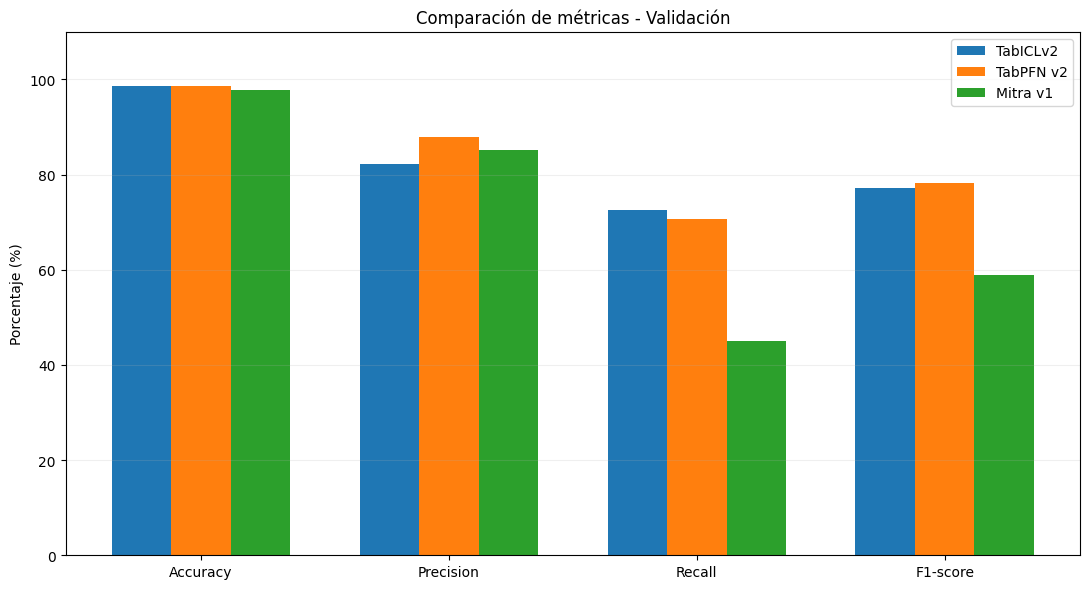

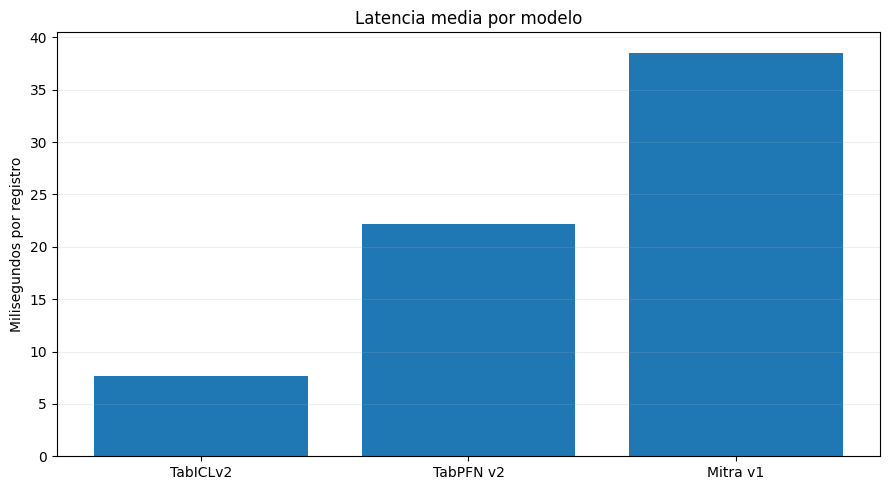

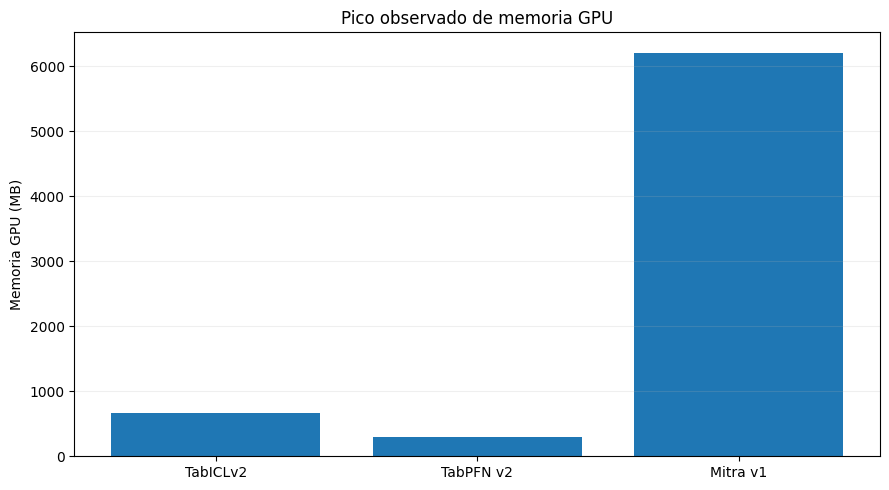

Gráficos guardados en: /content/pm_actividad4/results/figures


In [11]:
# BLOQUE 12 - COMPARACIÓN GLOBAL DE LOS TRES MODELOS

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Preparar directorios de resultados
BASE_DIR = Path("/content/pm_actividad4")
RESULTS_DIR = BASE_DIR / "results"
FIG_DIR = RESULTS_DIR / "figures"

FIG_DIR.mkdir(parents=True, exist_ok=True)

# Comprobar los tres modelos
MODELOS = ["TabICLv2", "TabPFN v2", "Mitra v1"]

assert set(MODELOS) == set(
    resultados_validacion["Modelo"]
), "Faltan resultados de algún modelo."

# Ordenar resultados
comparacion = (
    resultados_validacion
    .set_index("Modelo")
    .loc[MODELOS]
    .reset_index()
)

print("COMPARACIÓN GLOBAL - VALIDACIÓN")
display(comparacion.round(4))

# GRÁFICO 1: métricas predictivas
metricas = ["Accuracy", "Precision", "Recall", "F1-score"]
pos = np.arange(len(metricas))
ancho = 0.24

fig, ax = plt.subplots(figsize=(11, 6))

for i, modelo in enumerate(MODELOS):
    fila = comparacion.set_index("Modelo").loc[modelo]
    valores = [fila[m] * 100 for m in metricas]

    ax.bar(
        pos + (i - 1) * ancho,
        valores,
        width=ancho,
        label=modelo
    )

ax.set_xticks(pos)
ax.set_xticklabels(metricas)
ax.set_ylabel("Porcentaje (%)")
ax.set_ylim(0, 110)
ax.set_title("Comparación de métricas - Validación")
ax.legend()
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.savefig(FIG_DIR / "01_metricas_validacion.png", dpi=180)
plt.show()

# GRÁFICO 2: latencia
fig, ax = plt.subplots(figsize=(9, 5))

ax.bar(
    comparacion["Modelo"],
    comparacion["Latencia ms/registro"]
)

ax.set_title("Latencia media por modelo")
ax.set_ylabel("Milisegundos por registro")
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.savefig(FIG_DIR / "02_latencia_validacion.png", dpi=180)
plt.show()

# GRÁFICO 3: memoria GPU
fig, ax = plt.subplots(figsize=(9, 5))

ax.bar(
    comparacion["Modelo"],
    comparacion["Memoria GPU MB"]
)

ax.set_title("Pico observado de memoria GPU")
ax.set_ylabel("Memoria GPU (MB)")
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.savefig(FIG_DIR / "03_memoria_validacion.png", dpi=180)
plt.show()

print("Gráficos guardados en:", FIG_DIR)


## 13. Análisis y optimización de umbrales de decisión

### Objetivo
Determinar si es posible mejorar la detección de fallas modificando el umbral utilizado para convertir las probabilidades de cada modelo en predicciones binarias.

### Problema
El umbral inicial de 0.50 no necesariamente representa el equilibrio más adecuado entre falsas alarmas y fallas no detectadas.

En mantenimiento industrial, una falla no identificada puede generar consecuencias operativas superiores a las de una inspección innecesaria.

### Metodología
Se evaluarán umbrales entre 0.05 y 0.95, con incrementos de 0.01.

Para cada umbral se calcularán:
- Precision.
- Recall.
- F1-score.
- F2-score.
- Falsos positivos.
- Falsos negativos.

### Criterio de optimización
Se maximizará el F2-score, que otorga mayor importancia al recall que a la precision.

Para evitar un número excesivo de alertas, se exigirá una precision mínima de 0.50.

Esta restricción constituye una decisión experimental para el prototipo académico, no un requisito validado por una planta industrial real.

### Prevención de fuga de información
Los umbrales se seleccionarán exclusivamente mediante los datos de validación.

No se utilizará el conjunto de prueba para establecer o modificar los umbrales.

### Resultados esperados
- Umbral recomendado para cada modelo.
- Tabla de métricas optimizadas.
- Comparación frente al umbral 0.50.
- Curvas Precision-Recall.

### Relación con la rúbrica
Criterios 3 y 4: ajuste mínimo justificado, análisis del trade-off y evaluación contextualizada de los riesgos.

UMBRALES SELECCIONADOS EN VALIDACIÓN


,Modelo,Umbral,Precision,Recall,F1-score,F2-score,FP,FN,TP,TN
0,TabICLv2,0.25,0.7167,0.8431,0.7748,0.8144,17,8,43,1432
1,TabPFN v2,0.22,0.7000,0.8235,0.7568,0.7955,18,9,42,1431
2,Mitra v1,0.15,0.5190,0.8039,0.6308,0.7244,38,10,41,1411


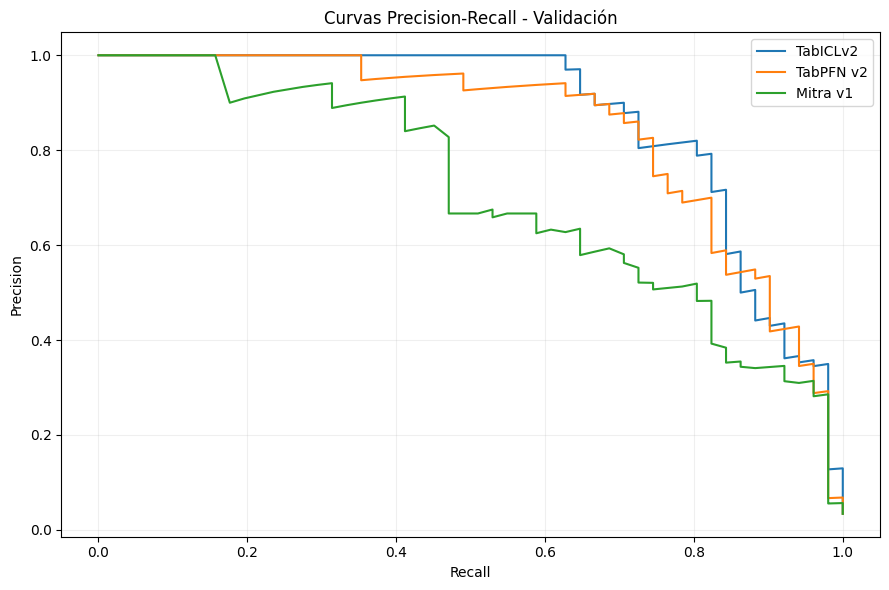

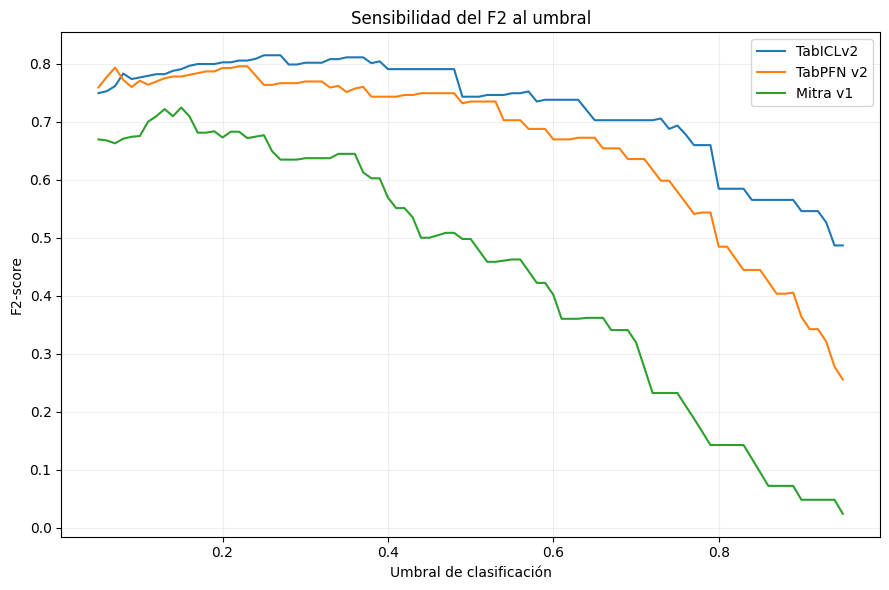


Optimización completada sin utilizar datos de prueba.


In [12]:
# BLOQUE 13 - OPTIMIZACIÓN DE UMBRALES

from sklearn.metrics import (
    f1_score, fbeta_score, precision_score,
    recall_score, confusion_matrix,
    precision_recall_curve
)

# Recuperar probabilidades calculadas anteriormente
probabilidades_val = {
    "TabICLv2": np.asarray(prob_falla),
    "TabPFN v2": np.asarray(prob_tabpfn),
    "Mitra v1": np.asarray(prob_mitra)
}

# Comprobar integridad
for nombre, probabilidades in probabilidades_val.items():
    assert len(probabilidades) == len(y_val)
    assert np.isfinite(probabilidades).all()
    assert ((probabilidades >= 0) &
            (probabilidades <= 1)).all()

# Definir criterios ANTES de la selección
PRECISION_MINIMA = 0.50
UMBRALES = np.round(np.arange(0.05, 0.951, 0.01), 2)

registros_umbrales = []
mejores_umbrales = []

for modelo, probabilidades in probabilidades_val.items():

    evaluaciones = []

    for umbral in UMBRALES:
        pred = (probabilidades >= umbral).astype(int)

        precision = precision_score(
            y_val, pred, zero_division=0
        )
        recall = recall_score(
            y_val, pred, zero_division=0
        )
        f1 = f1_score(
            y_val, pred, zero_division=0
        )
        f2 = fbeta_score(
            y_val, pred, beta=2, zero_division=0
        )

        tn, fp, fn, tp = confusion_matrix(
            y_val, pred, labels=[0, 1]
        ).ravel()

        fila = {
            "Modelo": modelo,
            "Umbral": float(umbral),
            "Precision": precision,
            "Recall": recall,
            "F1-score": f1,
            "F2-score": f2,
            "FP": int(fp),
            "FN": int(fn),
            "TP": int(tp),
            "TN": int(tn)
        }

        registros_umbrales.append(fila)
        evaluaciones.append(fila)

    tabla_modelo = pd.DataFrame(evaluaciones)

    # Exigir precisión mínima
    candidatos = tabla_modelo[
        tabla_modelo["Precision"] >= PRECISION_MINIMA
    ].copy()

    if candidatos.empty:
        raise ValueError(
            f"{modelo}: ningún umbral cumple la precisión mínima."
        )

    # Maximizar F2; desempatar con recall y precision
    mejor = candidatos.sort_values(
        ["F2-score", "Recall", "Precision", "Umbral"],
        ascending=[False, False, False, True]
    ).iloc[0]

    mejores_umbrales.append(mejor.to_dict())

# Consolidar resultados
resultados_umbrales = pd.DataFrame(registros_umbrales)
umbrales_optimos = pd.DataFrame(mejores_umbrales)

print("UMBRALES SELECCIONADOS EN VALIDACIÓN")
display(umbrales_optimos.round(4))

# Curvas Precision-Recall
fig, ax = plt.subplots(figsize=(9, 6))

for modelo, probabilidades in probabilidades_val.items():
    precision, recall, _ = precision_recall_curve(
        y_val, probabilidades
    )

    ax.plot(recall, precision, label=modelo)

ax.set_title("Curvas Precision-Recall - Validación")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()
plt.savefig(FIG_DIR / "04_precision_recall_validacion.png",
            dpi=180)
plt.show()

# Evolución del F2 según el umbral
fig, ax = plt.subplots(figsize=(9, 6))

for modelo in MODELOS:
    datos = resultados_umbrales[
        resultados_umbrales["Modelo"] == modelo
    ]

    ax.plot(
        datos["Umbral"],
        datos["F2-score"],
        label=modelo
    )

ax.set_title("Sensibilidad del F2 al umbral")
ax.set_xlabel("Umbral de clasificación")
ax.set_ylabel("F2-score")
ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()
plt.savefig(FIG_DIR / "05_optimizacion_umbrales.png",
            dpi=180)
plt.show()

print("\nOptimización completada sin utilizar datos de prueba.")


## 14. Selección técnica del modelo recomendado

### Objetivo
Seleccionar el modelo más adecuado para el prototipo mediante criterios definidos y resultados obtenidos exclusivamente sobre validación.

### Criterio principal
Se seleccionará el modelo con mayor F2-score después del ajuste de umbral.

Este criterio prioriza la detección de fallas, manteniendo una precision mínima de 0.50.

### Criterios secundarios
Cuando existan empates, se considerarán:
1. Mayor recall.
2. Mayor F1-score.
3. Menor latencia de inferencia.

### Justificación de negocio
El costo de no detectar una falla puede ser superior al costo de investigar una alerta que posteriormente resulta falsa.

Sin embargo, la relación real entre ambos costos depende de cada instalación industrial y no está disponible en el dataset.

### Análisis de eficiencia
Se contrastarán calidad predictiva, latencia y memoria GPU para determinar la viabilidad computacional del candidato.

### Precaución metodológica
La selección se realizará exclusivamente con datos de validación.

El conjunto de prueba se utilizará una sola vez para evaluar las configuraciones seleccionadas, sin reoptimizar umbrales ni cambiar la recomendación en función de esos resultados.

### Resultado esperado
- Ranking técnico de los tres modelos.
- Umbral recomendado.
- Modelo seleccionado antes de la evaluación final.
- Fundamentación de la decisión.

### Relación con la rúbrica
Criterios 3 y 4: análisis de trade-offs, selección fundamentada y documentación de las decisiones técnicas.

In [13]:
# BLOQUE 14 - SELECCIÓN DEL MODELO

# Integrar calidad predictiva y eficiencia
tabla_decision = umbrales_optimos.merge(
    resultados_validacion[
        ["Modelo", "Latencia ms/registro", "Memoria GPU MB"]
    ],
    on="Modelo",
    how="inner"
)

assert len(tabla_decision) == 3

# Criterios definidos antes del test
ranking = tabla_decision.sort_values(
    [
        "F2-score",
        "Recall",
        "F1-score",
        "Latencia ms/registro"
    ],
    ascending=[False, False, False, True]
).reset_index(drop=True)

ranking.insert(
    0, "Posición", np.arange(1, len(ranking) + 1)
)

modelo_seleccionado = str(ranking.iloc[0]["Modelo"])
umbral_seleccionado = float(ranking.iloc[0]["Umbral"])

# Guardar umbral de cada modelo para evaluación final
umbrales_por_modelo = dict(
    zip(
        umbrales_optimos["Modelo"],
        umbrales_optimos["Umbral"].astype(float)
    )
)

print("RANKING TÉCNICO SOBRE VALIDACIÓN")
display(ranking.round(4))

print("\nMODELO SELECCIONADO ANTES DEL TEST")
print("Modelo:", modelo_seleccionado)
print("Umbral:", round(umbral_seleccionado, 3))
print("F2 en validación:",
      round(float(ranking.iloc[0]["F2-score"]), 4))
print("Recall en validación:",
      round(float(ranking.iloc[0]["Recall"]), 4))
print("Precision en validación:",
      round(float(ranking.iloc[0]["Precision"]), 4))

print("\nCRITERIO DE SELECCIÓN")
print("Maximizar F2 con precision >= 0.50.")
print("Desempates: recall, F1 y menor latencia.")
print("La selección queda fijada antes de evaluar test.")

# Congelar la decisión y conservar trazabilidad
decision_final = {
    "Modelo seleccionado": modelo_seleccionado,
    "Umbral seleccionado": umbral_seleccionado,
    "Criterio": "F2 máximo con precision >= 0.50",
    "Conjunto utilizado": "Validación",
    "Semilla": SEED
}

RANKING TÉCNICO SOBRE VALIDACIÓN


,Posición,Modelo,Umbral,Precision,Recall,F1-score,F2-score,FP,FN,TP,TN,Latencia ms/registro,Memoria GPU MB
0,1,TabICLv2,0.25,0.7167,0.8431,0.7748,0.8144,17,8,43,1432,7.6545,669.6460
1,2,TabPFN v2,0.22,0.7000,0.8235,0.7568,0.7955,18,9,42,1431,22.1738,296.3408
2,3,Mitra v1,0.15,0.5190,0.8039,0.6308,0.7244,38,10,41,1411,38.5543,6209.1641



MODELO SELECCIONADO ANTES DEL TEST
Modelo: TabICLv2
Umbral: 0.25
F2 en validación: 0.8144
Recall en validación: 0.8431
Precision en validación: 0.7167

CRITERIO DE SELECCIÓN
Maximizar F2 con precision >= 0.50.
Desempates: recall, F1 y menor latencia.
La selección queda fijada antes de evaluar test.


## 15. Evaluación final sobre el conjunto independiente de prueba

### Objetivo
Evaluar la capacidad de generalización de los tres modelos utilizando los 1,500 registros de prueba que permanecieron separados durante la implementación y selección.

### Protocolo de evaluación
Se utilizarán:
- Los mismos datos de entrenamiento originales.
- Las mismas ocho variables predictoras.
- Los checkpoints y las configuraciones previamente definidas.
- Los umbrales determinados mediante validación.
- Los mismos 1,500 registros de prueba.

### Control de fuga de información
Los datos de prueba no se utilizarán para entrenar modelos, ajustar umbrales ni decidir qué modelo recomendar.

La selección ya fue fijada en el bloque 14.

### Metodología
Los modelos se cargarán secuencialmente para administrar la memoria GPU.

Se obtendrán probabilidades y predicciones de los tres candidatos.

Se calcularán:
1. Accuracy.
2. Precision.
3. Recall.
4. F1-score.
5. F2-score.
6. Balanced accuracy.
7. Average precision.
8. Falsos positivos y falsos negativos.
9. Latencia y memoria GPU observada.

### Comparabilidad
Cada modelo será evaluado sobre los mismos registros.

Las mediciones de latencia consideran el modelo cargado y se realizan por lotes después de un calentamiento.

Los resultados pueden variar debido a características de los modelos, al orden de ejecución y al entorno compartido de Google Colab.

### Resultados esperados
- Tabla final de tres modelos.
- Métricas con umbrales seleccionados.
- Predicciones individuales.
- Comparación frente al umbral inicial 0.50.

### Interpretación
El conjunto de prueba proporciona una estimación independiente del desempeño del prototipo bajo el dataset académico.

No permite afirmar directamente que el sistema tendrá el mismo desempeño con maquinaria industrial real.

### Relación con la rúbrica
Criterios 2, 3 y 4: implementación reproducible, evaluación rigurosa, comparación y justificación final.

In [14]:
# BLOQUE 15 - EVALUACIÓN FINAL DE LOS TRES MODELOS

import gc
import time
import torch
import numpy as np
import pandas as pd

from pathlib import Path
from tabicl import TabICLClassifier
from tabpfn import TabPFNClassifier
from tabpfn.constants import ModelVersion
from autogluon.tabular import TabularPredictor

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, fbeta_score, balanced_accuracy_score,
    average_precision_score, confusion_matrix
)

assert torch.cuda.is_available(), "Se requiere GPU CUDA."
assert len(X_test_model) == len(y_test) == 1500
assert set(umbrales_por_modelo) == set(MODELOS)

# Directorio donde quedó guardado Mitra
ruta_mitra_final = Path(ruta_mitra)

if not ruta_mitra_final.exists():
    raise FileNotFoundError(
        "No se encontró Mitra. Ejecuta nuevamente el bloque 10."
    )

# Liberar Mitra antes de comenzar la evaluación secuencial
if "mitra_predictor" in globals():
    del mitra_predictor

gc.collect()
torch.cuda.empty_cache()

def liberar_memoria():
    """Liberar objetos temporales y caché CUDA."""
    gc.collect()
    torch.cuda.empty_cache()

def evaluar_modelo_test(nombre, modelo, funcion_prediccion):
    """
    Evaluar un modelo preparado sobre el mismo test.
    El umbral se obtuvo previamente en validación.
    """

    # Calentamiento no contabilizado en la latencia
    _ = funcion_prediccion(
        modelo, X_test_model.iloc[:8], 128
    )
    torch.cuda.synchronize()
    torch.cuda.reset_peak_memory_stats()

    inicio = time.perf_counter()

    probabilidades = funcion_prediccion(
        modelo, X_test_model, 128
    )

    torch.cuda.synchronize()
    duracion = time.perf_counter() - inicio

    probabilidades = np.asarray(probabilidades)

    assert len(probabilidades) == len(y_test)
    assert np.isfinite(probabilidades).all()

    umbral = float(umbrales_por_modelo[nombre])
    predicciones = (
        probabilidades >= umbral
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test, predicciones, labels=[0, 1]
    ).ravel()

    metricas = {
        "Modelo": nombre,
        "Umbral": umbral,
        "Accuracy": accuracy_score(
            y_test, predicciones
        ),
        "Precision": precision_score(
            y_test, predicciones, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predicciones, zero_division=0
        ),
        "F1-score": f1_score(
            y_test, predicciones, zero_division=0
        ),
        "F2-score": fbeta_score(
            y_test, predicciones, beta=2,
            zero_division=0
        ),
        "Balanced Accuracy": balanced_accuracy_score(
            y_test, predicciones
        ),
        "Average Precision": average_precision_score(
            y_test, probabilidades
        ),
        "TN": int(tn),
        "FP": int(fp),
        "FN": int(fn),
        "TP": int(tp),
        "Tiempo inferencia s": duracion,
        "Latencia ms/registro":
            duracion / len(y_test) * 1000,
        "Memoria GPU MB":
            torch.cuda.max_memory_allocated() / 1024**2
    }

    return metricas, probabilidades, predicciones


metricas_test = []
probabilidades_test = {}
predicciones_test = {}

# MODELO 1: TabICLv2
print("1/3 - Evaluando TabICLv2...")

modelo_t1 = TabICLClassifier(
    device="cuda",
    checkpoint_version="tabicl-classifier-v2-20260212.ckpt",
    n_estimators=4,
    batch_size=2,
    random_state=SEED
)

modelo_t1.fit(
    X_train_model, y_train.to_numpy()
)

resultado, prob, pred = evaluar_modelo_test(
    "TabICLv2",
    modelo_t1,
    predecir_por_lotes
)

metricas_test.append(resultado)
probabilidades_test["TabICLv2"] = prob
predicciones_test["TabICLv2"] = pred

del modelo_t1
liberar_memoria()

# MODELO 2: TabPFN v2
print("\n2/3 - Evaluando TabPFN v2...")

modelo_t2 = TabPFNClassifier.create_default_for_version(
    ModelVersion.V2,
    device="cuda",
    n_estimators=4,
    random_state=SEED,
    fit_mode="low_memory"
)

modelo_t2.fit(
    X_train_model, y_train.to_numpy()
)

resultado, prob, pred = evaluar_modelo_test(
    "TabPFN v2",
    modelo_t2,
    predecir_tabpfn_por_lotes
)

metricas_test.append(resultado)
probabilidades_test["TabPFN v2"] = prob
predicciones_test["TabPFN v2"] = pred

del modelo_t2
liberar_memoria()

# MODELO 3: Mitra v1
print("\n3/3 - Evaluando Mitra v1...")

modelo_t3 = TabularPredictor.load(
    str(ruta_mitra_final)
)

resultado, prob, pred = evaluar_modelo_test(
    "Mitra v1",
    modelo_t3,
    predecir_mitra_por_lotes
)

metricas_test.append(resultado)
probabilidades_test["Mitra v1"] = prob
predicciones_test["Mitra v1"] = pred

del modelo_t3
liberar_memoria()

# Consolidar resultados finales
resultados_test = (
    pd.DataFrame(metricas_test)
    .set_index("Modelo")
    .loc[MODELOS]
    .reset_index()
)

print("\nRESULTADOS FINALES - CONJUNTO DE PRUEBA")
display(resultados_test.round(4))

# Registrar probabilidades y predicciones por observación
predicciones_finales = pd.DataFrame({
    "indice_original": X_test_model.index,
    "valor_real": y_test.to_numpy()
})

for nombre in MODELOS:
    predicciones_finales[
        f"{nombre} - probabilidad"
    ] = probabilidades_test[nombre]

    predicciones_finales[
        f"{nombre} - predicción"
    ] = predicciones_test[nombre]

# Comparación adicional con el umbral 0.50
metricas_base_test = []

for nombre in MODELOS:
    pred_050 = (
        probabilidades_test[nombre] >= 0.50
    ).astype(int)

    metricas_base_test.append({
        "Modelo": nombre,
        "Umbral": 0.50,
        "Precision": precision_score(
            y_test, pred_050, zero_division=0
        ),
        "Recall": recall_score(
            y_test, pred_050, zero_division=0
        ),
        "F1-score": f1_score(
            y_test, pred_050, zero_division=0
        ),
        "F2-score": fbeta_score(
            y_test, pred_050, beta=2,
            zero_division=0
        )
    })

resultados_test_050 = pd.DataFrame(metricas_base_test)

print("\nREFERENCIA: TEST CON UMBRAL 0.50")
display(resultados_test_050.round(4))

print("\nSELECCIÓN REALIZADA EN VALIDACIÓN:")
print(modelo_seleccionado)
print("Umbral seleccionado:", umbral_seleccionado)
print("\nLa selección NO se modifica con los resultados de test.")

1/3 - Evaluando TabICLv2...

2/3 - Evaluando TabPFN v2...

3/3 - Evaluando Mitra v1...

RESULTADOS FINALES - CONJUNTO DE PRUEBA


,Modelo,Umbral,Accuracy,Precision,Recall,F1-score,F2-score,Balanced Accuracy,Average Precision,TN,FP,FN,TP,Tiempo inferencia s,Latencia ms/registro,Memoria GPU MB
0,TabICLv2,0.25,0.9873,0.8077,0.8235,0.8155,0.8203,0.9083,0.8610,1439,10,9,42,11.0899,7.3933,669.5210
1,TabPFN v2,0.22,0.9847,0.7500,0.8235,0.7850,0.8077,0.9069,0.8463,1435,14,9,42,34.2107,22.8071,296.3408
2,Mitra v1,0.15,0.9647,0.4878,0.7843,0.6015,0.6993,0.8777,0.7240,1407,42,11,40,57.3152,38.2101,6208.2891



REFERENCIA: TEST CON UMBRAL 0.50


,Modelo,Umbral,Precision,Recall,F1-score,F2-score
0,TabICLv2,0.5,0.9250,0.7255,0.8132,0.7582
1,TabPFN v2,0.5,0.8947,0.6667,0.7640,0.7025
2,Mitra v1,0.5,0.8276,0.4706,0.6000,0.5150



SELECCIÓN REALIZADA EN VALIDACIÓN:
TabICLv2
Umbral seleccionado: 0.25

La selección NO se modifica con los resultados de test.


## 16. Análisis final de desempeño, errores y eficiencia

### Objetivo
Interpretar los resultados finales mediante visualizaciones que relacionen la capacidad de detección de fallas, los errores de clasificación y el costo computacional de los modelos.

### Visualizaciones
Se generarán:

1. Matrices de confusión de los tres modelos.
2. Comparación de precision, recall y F1-score.
3. Curvas Precision-Recall sobre datos de prueba.
4. Relación entre F1-score y latencia.
5. Análisis ilustrativo de costos relativos de errores.

### Riesgo operativo
Los falsos negativos representan fallas no identificadas y pueden ocasionar mantenimiento correctivo no planificado.

Los falsos positivos representan alertas incorrectas y pueden provocar revisiones innecesarias.

### Análisis económico de sensibilidad
Dado que el dataset no proporciona costos monetarios por falla o inspección, se utilizará un escenario hipotético con una relación de costo de 10 a 1 entre falsos negativos y falsos positivos.

Los valores serán unidades relativas, no estimaciones monetarias reales.

Este escenario se utilizará únicamente para interpretar las consecuencias operativas de los errores; no modificará la selección previamente establecida.

### Consideraciones estadísticas
El conjunto de prueba contiene únicamente 51 fallas reales.

Por esta razón, pequeñas diferencias en la detección de fallas pueden modificar significativamente el recall.

Los resultados deberán interpretarse como evidencia académica del dataset evaluado y no como garantías de desempeño industrial.

### Relación con la rúbrica
Criterios 3 y 4: comparación visual, análisis de trade-offs, interpretación aplicada y riesgos del modelo recomendado.

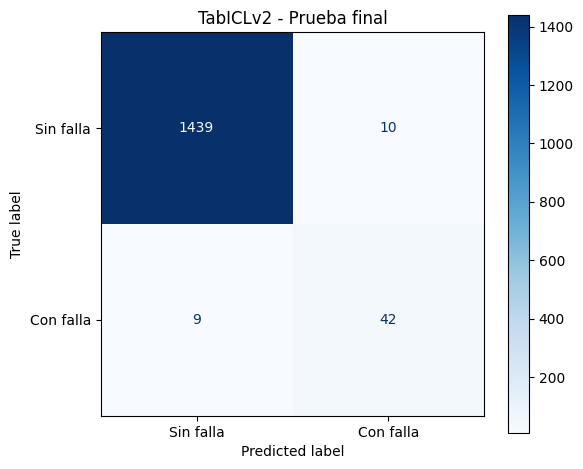

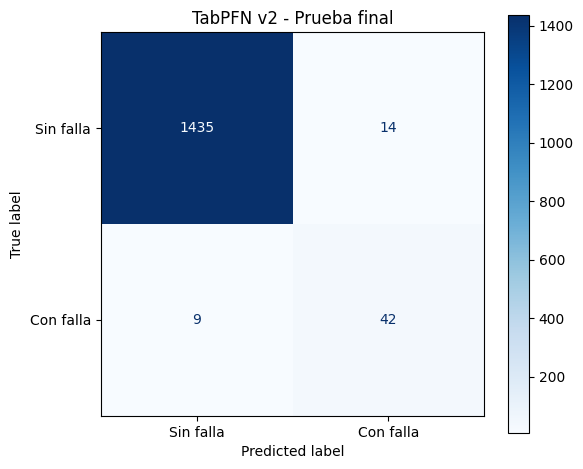

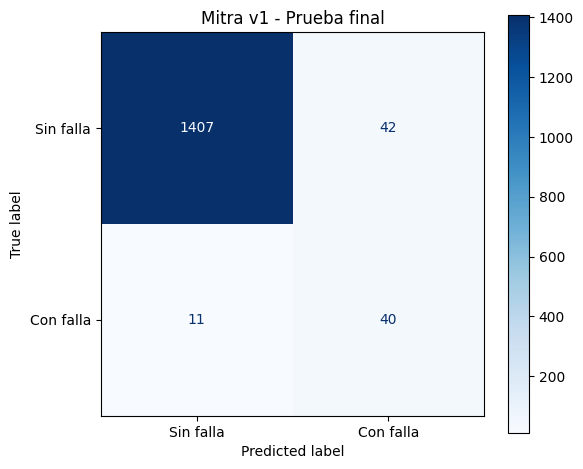

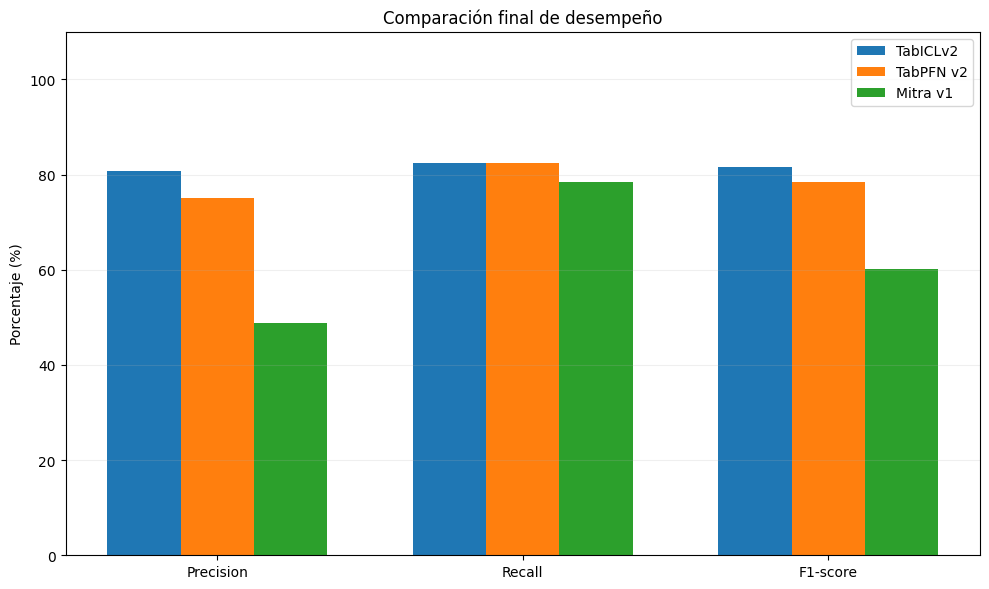

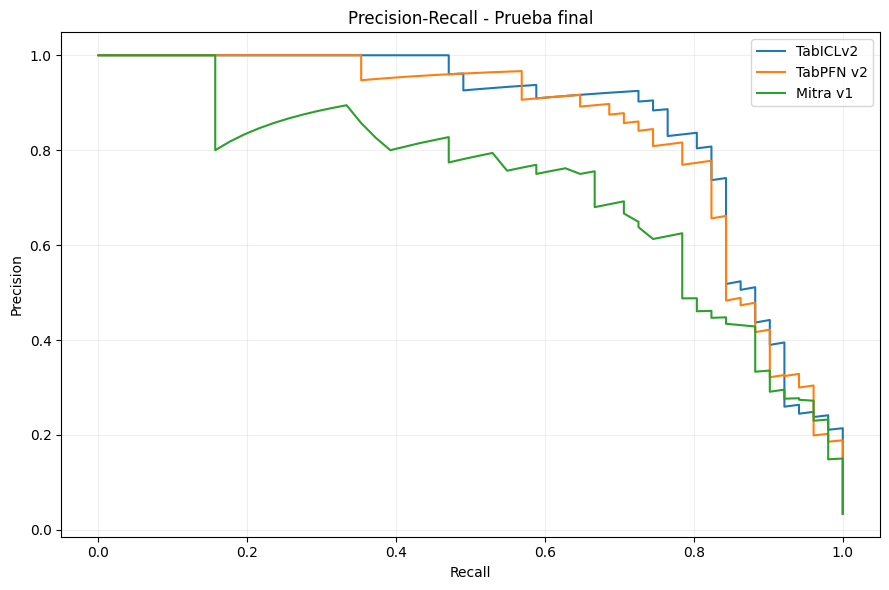

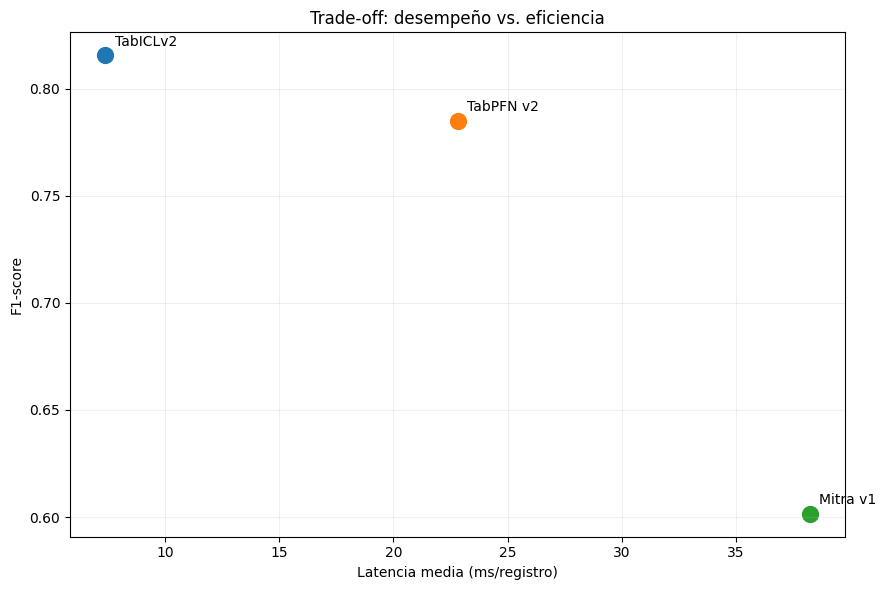

ESCENARIO HIPOTÉTICO DE COSTOS
Costo FP = 1 unidad relativa
Costo FN = 10 unidades relativas


,Modelo,FP,FN,Costo relativo
0,TabICLv2,10,9,100
1,TabPFN v2,14,9,104
2,Mitra v1,42,11,152


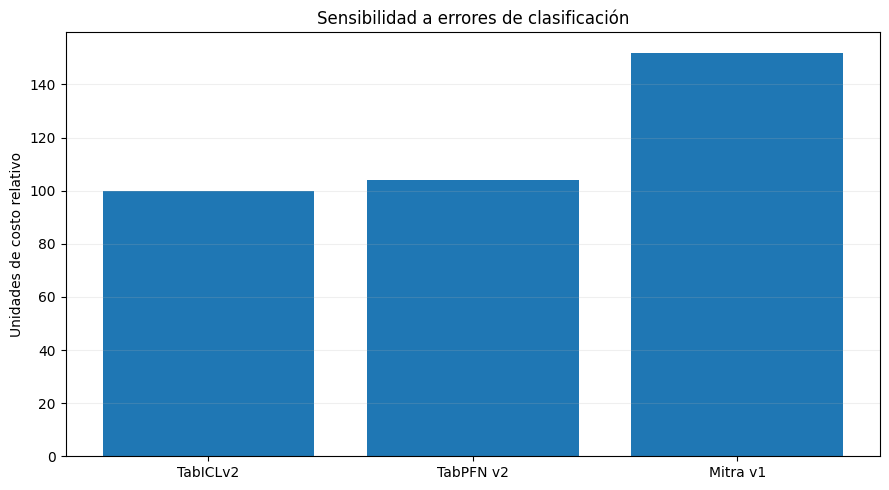


ANÁLISIS FINAL COMPLETADO
Modelo elegido en validación: TabICLv2
Se mantiene la selección previamente establecida.


In [15]:
# BLOQUE 16 - VISUALIZACIONES Y RIESGO OPERATIVO

from sklearn.metrics import (
    confusion_matrix, ConfusionMatrixDisplay,
    precision_recall_curve
)

# MATRICES DE CONFUSIÓN
for nombre in MODELOS:

    pred = predicciones_test[nombre]

    matriz = confusion_matrix(
        y_test, pred, labels=[0, 1]
    )

    fig, ax = plt.subplots(figsize=(6, 5))

    ConfusionMatrixDisplay(
        confusion_matrix=matriz,
        display_labels=["Sin falla", "Con falla"]
    ).plot(
        ax=ax,
        cmap="Blues",
        values_format="d"
    )

    ax.set_title(f"{nombre} - Prueba final")

    archivo = nombre.lower().replace(" ", "_")
    plt.tight_layout()
    plt.savefig(
        FIG_DIR / f"06_matriz_{archivo}.png",
        dpi=180
    )
    plt.show()

# COMPARACIÓN DE MÉTRICAS
metricas_grafico = ["Precision", "Recall", "F1-score"]
pos = np.arange(len(metricas_grafico))
ancho = 0.24

fig, ax = plt.subplots(figsize=(10, 6))

for i, nombre in enumerate(MODELOS):
    fila = resultados_test.set_index("Modelo").loc[nombre]
    valores = [
        fila[metrica] * 100
        for metrica in metricas_grafico
    ]

    ax.bar(
        pos + (i - 1) * ancho,
        valores,
        width=ancho,
        label=nombre
    )

ax.set_xticks(pos)
ax.set_xticklabels(metricas_grafico)
ax.set_ylim(0, 110)
ax.set_ylabel("Porcentaje (%)")
ax.set_title("Comparación final de desempeño")
ax.legend()
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.savefig(
    FIG_DIR / "07_comparacion_final.png",
    dpi=180
)
plt.show()

# CURVAS PRECISION-RECALL
fig, ax = plt.subplots(figsize=(9, 6))

for nombre in MODELOS:
    precision, recall, _ = precision_recall_curve(
        y_test, probabilidades_test[nombre]
    )

    ax.plot(recall, precision, label=nombre)

ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("Precision-Recall - Prueba final")
ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()
plt.savefig(
    FIG_DIR / "08_precision_recall_test.png",
    dpi=180
)
plt.show()

# TRADE-OFF ENTRE F1 Y LATENCIA
fig, ax = plt.subplots(figsize=(9, 6))

for _, fila in resultados_test.iterrows():
    ax.scatter(
        fila["Latencia ms/registro"],
        fila["F1-score"],
        s=130
    )

    ax.annotate(
        fila["Modelo"],
        (
            fila["Latencia ms/registro"],
            fila["F1-score"]
        ),
        xytext=(7, 7),
        textcoords="offset points"
    )

ax.set_xlabel("Latencia media (ms/registro)")
ax.set_ylabel("F1-score")
ax.set_title("Trade-off: desempeño vs. eficiencia")
ax.grid(alpha=0.2)

plt.tight_layout()
plt.savefig(
    FIG_DIR / "09_tradeoff_eficiencia.png",
    dpi=180
)
plt.show()

# ESCENARIO ILUSTRATIVO DE COSTOS RELATIVOS
# No representa costos reales de una planta.
COSTO_RELATIVO_FP = 1
COSTO_RELATIVO_FN = 10

riesgos = resultados_test[
    ["Modelo", "FP", "FN"]
].copy()

riesgos["Costo relativo"] = (
    riesgos["FP"] * COSTO_RELATIVO_FP +
    riesgos["FN"] * COSTO_RELATIVO_FN
)

print("ESCENARIO HIPOTÉTICO DE COSTOS")
print("Costo FP = 1 unidad relativa")
print("Costo FN = 10 unidades relativas")
display(riesgos)

fig, ax = plt.subplots(figsize=(9, 5))

ax.bar(
    riesgos["Modelo"],
    riesgos["Costo relativo"]
)

ax.set_ylabel("Unidades de costo relativo")
ax.set_title("Sensibilidad a errores de clasificación")
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.savefig(
    FIG_DIR / "10_costos_relativos.png",
    dpi=180
)
plt.show()

print("\nANÁLISIS FINAL COMPLETADO")
print("Modelo elegido en validación:", modelo_seleccionado)
print("Se mantiene la selección previamente establecida.")

### 16.1. Intervalos de confianza e incertidumbre estadística

**Objetivo:** cuantificar la incertidumbre de las métricas de detección de falla sobre **51 casos positivos** del conjunto de prueba. Se calcula un intervalo Wilson del 95% para el recall de cada modelo y un *bootstrap pareado* de la diferencia de F1 entre TabICLv2 y TabPFN v2. Se mantienen los umbrales previamente seleccionados.

Se usa remuestreo de **las mismas observaciones para ambos modelos**, preservando su dependencia. Las diferencias no se presentan como estadísticamente significativas a menos que la evidencia lo sustente. Se evita volver a entrenar o seleccionar modelos usando prueba.

In [ ]:
# BLOQUE 16.1 - INCERTIDUMBRE ESTADÍSTICA, SIN REENTRENAMIENTO
from math import sqrt
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def wilson_interval(k, n, z=1.959963984540054):
    if n == 0: return (np.nan, np.nan)
    p = k / n
    d = 1 + z*z/n
    center = (p + z*z/(2*n)) / d
    m = z * sqrt((p*(1-p)+z*z/(4*n))/n)/d
    return (max(0,center-m), min(1,center+m))

n_fallas = int(np.sum(y_test.to_numpy() == 1))
assert n_fallas == 51
filas_ic = []
for _, r in resultados_test.iterrows():
    inferior, superior = wilson_interval(int(r["TP"]), n_fallas)
    filas_ic.append({
        "Modelo":r["Modelo"],"Fallas reales":n_fallas,
        "Fallas detectadas":int(r["TP"]),"Recall":float(r["Recall"]),
        "IC95 inferior":inferior,"IC95 superior":superior,
        "Método":"Wilson binomial; aproximación descriptiva"
    })
intervalos_recall = pd.DataFrame(filas_ic)
print("INTERVALOS DE RECALL (IC 95% WILSON)")
display(intervalos_recall.round(4))

# Bootstrap pareado del delta de F1 (TabICLv2 - TabPFN v2).
rng = np.random.default_rng(42)
verdad = y_test.to_numpy(dtype=int)
pa = np.asarray(predicciones_test["TabICLv2"],dtype=int)
pb = np.asarray(predicciones_test["TabPFN v2"],dtype=int)
bootstrap_deltas = []
def f1_bin(y,p):
    tp = int(np.sum((y==1)&(p==1)))
    fp = int(np.sum((y==0)&(p==1)))
    fn = int(np.sum((y==1)&(p==0)))
    return 2*tp/(2*tp+fp+fn) if 2*tp+fp+fn else 0.0
for _ in range(2000):
    indices = rng.integers(0,len(verdad),len(verdad))
    bootstrap_deltas.append(
        f1_bin(verdad[indices],pa[indices]) -
        f1_bin(verdad[indices],pb[indices])
    )
delta_obs = f1_bin(verdad,pa)-f1_bin(verdad,pb)
limites = np.quantile(bootstrap_deltas,[0.025,0.975])
comparacion_bootstrap = pd.DataFrame([{
    "Comparación":"TabICLv2 - TabPFN v2",
    "Métrica":"Diferencia de F1-score",
    "Delta observado":delta_obs,
    "IC95 bootstrap inferior":limites[0],
    "IC95 bootstrap superior":limites[1],
    "Repeticiones":2000,
    "Semilla":42,
    "Método":"Bootstrap pareado percentil por registros"
}])
print("DIFERENCIA DE F1: BOOTSTRAP PAREADO")
display(comparacion_bootstrap.round(4))
print("Un IC que cruza cero NO respalda superioridad estadística concluyente.")

fig,ax=plt.subplots(figsize=(9,5))
for j,r in intervalos_recall.iterrows():
    p=float(r["Recall"])
    ax.errorbar(p,j,xerr=[[p-r["IC95 inferior"]],[r["IC95 superior"]-p]],
                fmt="o",capsize=5)
ax.set_yticks(range(len(intervalos_recall)),intervalos_recall["Modelo"])
ax.set_xlim(0,1);ax.set_xlabel("Recall con IC 95% (Wilson)")
ax.set_title("Incertidumbre del recall: 51 fallas en prueba")
ax.grid(axis="x",alpha=.2)
plt.tight_layout()
plt.savefig(FIG_DIR/"12_intervalos_recall.svg")
plt.show()

### 16.2. Sensibilidad de costos relativos de falsos positivos y negativos

**Objetivo:** explorar cómo varía un indicador de costo relativo al cambiar **la penalización de un falso negativo**. No son pesos mexicanos ni costos observados; se utiliza FP = 1 unidad y FN en {1, 2, 5, 10, 20, 50, 100} unidades relativas.

El indicador es \`costo_relativo = FP × 1 + FN × penalización_FN\`. El ejercicio usa exclusivamente las predicciones ya emitidas y **no cambia la elección del modelo tomada en validación**.

Esto revela qué decisiones son sensibles al costo operativo y cuáles conservan su ventaja bajo distintos supuestos. Para una decisión económica real faltaría cuantificar paros, intervenciones y daños por máquina.

In [ ]:
# BLOQUE 16.2 - SENSIBILIDAD ECONÓMICA SIN DATOS FINANCIEROS INVENTADOS
from itertools import product
RATIOS = [1,2,5,10,20,50,100]
filas_costos = []
for ratio in RATIOS:
    for _,r in resultados_test.iterrows():
        filas_costos.append({
            "Modelo":r["Modelo"],"Costo unitario FP":1,
            "Costo unitario FN":ratio,
            "FP":int(r["FP"]),"FN":int(r["FN"]),
            "Costo relativo total":int(r["FP"])+ratio*int(r["FN"]),
            "Nota":"Escenario ilustrativo; no valores monetarios"
        })
sensibilidad_costos = pd.DataFrame(filas_costos)
print("SENSIBILIDAD: COSTO RELATIVO DEL ERROR")
display(sensibilidad_costos.pivot(
    index="Costo unitario FN",columns="Modelo",values="Costo relativo total"
))
fig,ax=plt.subplots(figsize=(9,5))
for m in MODELOS:
    sub=sensibilidad_costos[sensibilidad_costos["Modelo"]==m]
    ax.plot(sub["Costo unitario FN"],sub["Costo relativo total"],
            marker="o",label=m)
ax.set_xlabel("Costo relativo de FN (FP = 1)")
ax.set_ylabel("Costo relativo total (unidades)")
ax.set_title("Sensibilidad del costo por errores de clasificación")
ax.grid(alpha=.2);ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR/"11_costo_sensibilidad.svg")
plt.show()
print("El escenario se basa en los modelos/umbrales YA seleccionados.")

## 17. Exportación de dataset, resultados y configuración experimental

### Objetivo
Generar archivos reproducibles que permitan consultar el dataset, verificar las particiones, analizar las predicciones y documentar el entorno utilizado.

### Dataset
Se exportará el dataset AI4I 2020, incluyendo sus seis variables predictoras y la etiqueta de falla.

También se generará un registro de las particiones utilizadas para entrenamiento, validación y prueba.

### Resultados
Se exportarán:
- Métricas iniciales de validación.
- Resultados de optimización de umbrales.
- Ranking de selección.
- Métricas finales de prueba.
- Predicciones individuales del conjunto de prueba.
- Análisis de costos relativos.

### Reproducibilidad
Se documentarán:
- Versiones de las bibliotecas.
- Semilla aleatoria.
- Dispositivo de ejecución.
- Distribución de los conjuntos.
- Identificadores de los modelos.
- Configuraciones relevantes.

### Consideraciones
Los pesos de los modelos no serán incluidos en el repositorio debido a su tamaño.

Se utilizarán las bibliotecas correspondientes para recuperar los checkpoints desde Hugging Face cuando sea necesario.

Los archivos CSV contendrán únicamente información del dataset académico sintético.

### Relación con la rúbrica
Criterios 2 y 4: reproducibilidad, documentación del dataset, scripts de soporte, estructura del repositorio y trazabilidad de resultados.

In [17]:
# BLOQUE 17 - EXPORTACIÓN Y REPRODUCIBILIDAD

import json
import sys
import platform
import importlib.metadata as metadata
from datetime import datetime, timezone
from pathlib import Path

DATA_DIR = BASE_DIR / "data"
DOCS_DIR = BASE_DIR / "docs"
SRC_DIR = BASE_DIR / "src"

for carpeta in [DATA_DIR, DOCS_DIR, SRC_DIR, RESULTS_DIR]:
    carpeta.mkdir(parents=True, exist_ok=True)

# 1. EXPORTAR DATASET ACADÉMICO
archivo_dataset = DATA_DIR / "ai4i2020.csv"
df.to_csv(archivo_dataset, index=False)

# 2. REGISTRAR PARTICIONES EXPERIMENTALES
particiones = pd.concat([
    pd.DataFrame({
        "indice_original": X_train.index,
        "conjunto": "train",
        "machine_failure": y_train.to_numpy()
    }),
    pd.DataFrame({
        "indice_original": X_val.index,
        "conjunto": "validation",
        "machine_failure": y_val.to_numpy()
    }),
    pd.DataFrame({
        "indice_original": X_test.index,
        "conjunto": "test",
        "machine_failure": y_test.to_numpy()
    })
], ignore_index=True)

assert len(particiones) == len(df)
assert particiones["indice_original"].nunique() == len(df)

particiones.to_csv(
    DATA_DIR / "data_splits.csv",
    index=False
)

# 3. EXPORTAR RESULTADOS
archivos_csv = {
    "validation_metrics.csv": resultados_validacion,
    "confidence_intervals.csv": intervalos_recall,
    "paired_bootstrap.csv": comparacion_bootstrap,
    "cost_sensitivity.csv": sensibilidad_costos,
    "threshold_grid.csv": resultados_umbrales,
    "selected_thresholds.csv": umbrales_optimos,
    "model_ranking.csv": ranking,
    "test_metrics.csv": resultados_test,
    "test_metrics_threshold_050.csv": resultados_test_050,
    "test_predictions.csv": predicciones_finales,
    "risk_sensitivity.csv": riesgos
}

for nombre, tabla in archivos_csv.items():
    tabla.to_csv(RESULTS_DIR / nombre, index=False)

# 4. VERSIONES DE DEPENDENCIAS
paquetes = [
    "numpy",
    "pandas",
    "scikit-learn",
    "matplotlib",
    "ucimlrepo",
    "huggingface_hub",
    "tabicl",
    "tabpfn",
    "autogluon.tabular",
    "torch"
]

versiones = {}

for paquete in paquetes:
    try:
        versiones[paquete] = metadata.version(paquete)
    except metadata.PackageNotFoundError:
        versiones[paquete] = "No disponible"

# 5. REGISTRAR ENTORNO
entorno = {
    "proyecto": "Predictive Maintenance AI - Actividad 4",
    "fecha_utc": datetime.now(
        timezone.utc
    ).isoformat(),
    "python": sys.version,
    "sistema": platform.platform(),
    "gpu": torch.cuda.get_device_name(0),
    "semilla": SEED,
    "registros": len(df),
    "entrenamiento": len(X_train),
    "validacion": len(X_val),
    "prueba": len(X_test),
    "variables_originales": list(X.columns),
    "variables_procesadas": list(X_train_model.columns),
    "versiones": versiones,
    "repositorios_huggingface": {
    "TabICLv2": "jingang/TabICL",
    "TabPFN v2": "Prior-Labs/TabPFN-v2-clf",
    "Mitra v1": "autogluon/mitra-classifier"
},
    "umbrales": umbrales_por_modelo,
    "modelo_seleccionado": modelo_seleccionado,
    "criterio_seleccion": decision_final["Criterio"],
    "autenticacion_huggingface": globals().get("HF_AUTH_STATUS", "No documentada"),
    "checkpoint_tabicl_v2": "tabicl-classifier-v2-20260212.ckpt",
    "observacion_mitra": (
        "AutoGluon redujo el soporte de contexto "
        "de 8192 a 4096 durante la ejecución "
        "por restricciones de memoria."
    )
}

with open(
    DOCS_DIR / "environment.json",
    "w",
    encoding="utf-8"
) as archivo:
    json.dump(
        entorno, archivo,
        indent=2, ensure_ascii=False
    )

# 6. GENERAR REQUIREMENTS.TXT
# PyTorch se documenta en environment.json y se utiliza
# desde el entorno CUDA proporcionado por Google Colab.

paquetes_requirements = {
    "numpy": "numpy",
    "pandas": "pandas",
    "scikit-learn": "scikit-learn",
    "matplotlib": "matplotlib",
    "ucimlrepo": "ucimlrepo",
    "huggingface_hub": "huggingface_hub",
    "tabicl": "tabicl",
    "tabpfn": "tabpfn",
    "autogluon.tabular": "autogluon.tabular[mitra]"
}

lineas_requirements = [
    "# Dependencias utilizadas en Google Colab",
    "# PyTorch/CUDA se proveen mediante el runtime de Colab.",
    "# Consultar docs/environment.json para la versión de torch."
]

for paquete, especificacion in paquetes_requirements.items():
    version = versiones[paquete]

    if version == "No disponible":
        raise RuntimeError(
            f"No se pudo identificar la versión de {paquete}"
        )

    lineas_requirements.append(
        f"{especificacion}=={version}"
    )

(BASE_DIR / "requirements.txt").write_text(
    "\n".join(lineas_requirements) + "\n",
    encoding="utf-8"
)

# 7. CREAR SCRIPT REUTILIZABLE DE EVALUACIÓN
codigo_evaluacion = '''
"""Funciones de evaluación para clasificación binaria."""

import numpy as np
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    fbeta_score,
    confusion_matrix
)

def evaluar_clasificador(y_real, probabilidades, umbral=0.5):
    """Evaluar probabilidades de la clase de falla."""

    probabilidades = np.asarray(probabilidades)
    predicciones = (probabilidades >= umbral).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_real, predicciones, labels=[0, 1]
    ).ravel()

    return {
        "accuracy": accuracy_score(y_real, predicciones),
        "precision": precision_score(
            y_real, predicciones, zero_division=0
        ),
        "recall": recall_score(
            y_real, predicciones, zero_division=0
        ),
        "f1": f1_score(
            y_real, predicciones, zero_division=0
        ),
        "f2": fbeta_score(
            y_real, predicciones, beta=2,
            zero_division=0
        ),
        "TN": int(tn),
        "FP": int(fp),
        "FN": int(fn),
        "TP": int(tp)
    }
'''

(SRC_DIR / "evaluation.py").write_text(
    codigo_evaluacion.strip() + "\n",
    encoding="utf-8"
)

print("ARCHIVOS EXPORTADOS CORRECTAMENTE")
print("\nDataset:", archivo_dataset)
print("Directorio de resultados:", RESULTS_DIR)
print("Configuración:", DOCS_DIR / "environment.json")
print("Dependencias:", BASE_DIR / "requirements.txt")

print("\nResumen de archivos:")
for archivo in sorted(BASE_DIR.rglob("*")):
    if archivo.is_file():
        print(archivo.relative_to(BASE_DIR))

ARCHIVOS EXPORTADOS CORRECTAMENTE

Dataset: /content/pm_actividad4/data/ai4i2020.csv
Directorio de resultados: /content/pm_actividad4/results
Configuración: /content/pm_actividad4/docs/environment.json
Dependencias: /content/pm_actividad4/requirements.txt

Resumen de archivos:
data/ai4i2020.csv
data/data_splits.csv
docs/environment.json
requirements.txt
results/figures/01_metricas_validacion.png
results/figures/02_latencia_validacion.png
results/figures/03_memoria_validacion.png
results/figures/04_precision_recall_validacion.png
results/figures/05_optimizacion_umbrales.png
results/figures/06_matriz_mitra_v1.png
results/figures/06_matriz_tabiclv2.png
results/figures/06_matriz_tabpfn_v2.png
results/figures/07_comparacion_final.png
results/figures/08_precision_recall_test.png
results/figures/09_tradeoff_eficiencia.png
results/figures/10_costos_relativos.png
results/model_ranking.csv
results/risk_sensitivity.csv
results/selected_thresholds.csv
results/test_metrics.csv
results/test_metrics_

### 17.1. Trazabilidad de fuentes, pesos y autenticación

Se registran revisiones actuales del Hub mediante \`HfApi.model_info\` y resúmenes SHA-256 de archivos de pesos **solo cuando estos continúen accesibles en caché**. La revisión consultada en el momento de ejecutar **no necesariamente coincide** con la revisión descargada originalmente; esta limitación se identifica explícitamente.

No se incluyen pesos, tokens ni rutas con secretos en GitHub. El archivo \`docs/model_provenance.json\` y los hashes permiten auditar parte del entorno, pero la reproducción completa en una sesión limpia sigue siendo una verificación independiente pendiente hasta ejecutarla.

In [ ]:
# BLOQUE 17.1 - TRAZABILIDAD DE PESOS, NO CONFUNDIR REVISIÓN CONSULTADA Y USADA
import hashlib, json
from pathlib import Path
from huggingface_hub import HfApi
def hash_archivo(ruta):
    sha=hashlib.sha256()
    with open(ruta,"rb") as f:
        for trozo in iter(lambda:f.read(8*1024*1024),b""):
            sha.update(trozo)
    return sha.hexdigest()
ids_hf={"TabICLv2":"jingang/TabICL",
        "TabPFN v2":"Prior-Labs/TabPFN-v2-clf",
        "Mitra v1":"autogluon/mitra-classifier"}
patrones = {
    "TabICLv2": [
        "/root/.cache/huggingface/hub/models--jingang--TabICL/snapshots/*/tabicl-classifier-v2-20260212.ckpt"],
    "TabPFN v2": ["/root/.cache/tabpfn/tabpfn-v2-classifier-finetuned-*.ckpt"],
    "Mitra v1": ["/root/.cache/huggingface/hub/models--autogluon--mitra-classifier/snapshots/*/model.safetensors"]
}
api=HfApi()
manifiesto={"autenticacion":globals().get("HF_AUTH_STATUS","No documentada"),
 "nota_revision":"SHA del Hub consultada ahora; no demuestra revisión usada en una corrida anterior.",
 "modelos":{},"dataset_sha256":hash_archivo(DATA_DIR/"ai4i2020.csv"),
 "splits_sha256":hash_archivo(DATA_DIR/"data_splits.csv")}
from glob import glob
for nombre,repoid in ids_hf.items():
    registro={"repo":repoid,"revision_consultada":None,"checkpoint_local":None}
    try:
        registro["revision_consultada"]=api.model_info(repoid).sha
    except Exception as exc:
        registro["consulta_error"]=type(exc).__name__
    hallados=sorted({p for patron in patrones[nombre] for p in glob(patron)})
    if hallados:
        ruta=Path(hallados[0])
        registro["checkpoint_local"]={
            "archivo":ruta.name,"bytes":ruta.stat().st_size,
            "sha256":hash_archivo(ruta)}
    else:
        registro["checkpoint_local"]={"estado":"No localizado en caché"}
    manifiesto["modelos"][nombre]=registro
(DOCS_DIR/"model_provenance.json").write_text(
    json.dumps(manifiesto,ensure_ascii=False,indent=2)+"\n",encoding="utf-8")
print("TRAZABILIDAD GUARDADA")
print("Autenticación:",manifiesto["autenticacion"])
for modelo,meta in manifiesto["modelos"].items():
    print(modelo,"Hub SHA consultado:",meta["revision_consultada"])
    print("  checkpoint local:",meta["checkpoint_local"])

## 18. Documentación final y preparación del repositorio GitHub

### Objetivo
Consolidar los resultados de la Actividad 4 en un repositorio organizado, reproducible y documentado.

### Documentación técnica
Se generará un README.md con:

1. Descripción del proyecto y problema de negocio.
2. Objetivos de la actividad.
3. Dataset y diccionario de variables.
4. Ecosistema Hugging Face.
5. Selección de modelos preentrenados.
6. Protocolo experimental.
7. Métricas iniciales de validación.
8. Optimización de umbrales.
9. Selección del modelo recomendado.
10. Resultados finales de prueba.
11. Trade-off entre precisión y eficiencia.
12. Riesgos y limitaciones.
13. Reproducibilidad.
14. Conclusiones y referencias.

### Estructura del repositorio
- notebooks: cuaderno ejecutable.
- data: dataset y particiones.
- results: métricas, predicciones y figuras.
- src: código reutilizable.
- docs: documentación del entorno y metodología.
- README.md: reporte técnico principal.
- requirements.txt: dependencias.

### Reproducibilidad
Se proporcionarán instrucciones para ejecutar el notebook en Google Colab con GPU.

Las dependencias y el entorno quedarán documentados.

### Alcance de las conclusiones
El modelo recomendado se habrá elegido mediante validación y posteriormente evaluado sobre datos de prueba.

Los resultados no constituyen evidencia de un despliegue productivo ni de capacidad de anticipación temporal sobre maquinaria real.

### Entrega
La entrega académica consistirá en la dirección URL del repositorio GitHub, que contendrá el notebook, dataset, resultados, documentación y archivos de soporte.

### Relación con la rúbrica
Criterio 4: documentación técnica estructurada, repositorio organizado, reproducibilidad y justificación final del modelo recomendado.

In [18]:
# BLOQUE 18 - README FINAL Y PREPARACIÓN DE GITHUB

import zipfile
from datetime import datetime, timezone

# Función para construir tablas Markdown sin dependencias extra
def tabla_markdown(datos, columnas, porcentajes=None):
    porcentajes = set(porcentajes or [])

    encabezado = "| " + " | ".join(columnas) + " |"
    separador = "| " + " | ".join(
        ["---"] * len(columnas)
    ) + " |"

    filas = []

    for _, fila in datos.iterrows():
        valores = []

        for columna in columnas:
            valor = fila[columna]

            if isinstance(valor, (int, float, np.number)):
                if columna in porcentajes:
                    texto = f"{float(valor) * 100:.2f}%"
                elif isinstance(valor, (int, np.integer)):
                    texto = str(int(valor))
                else:
                    texto = f"{float(valor):.3f}"
            else:
                texto = str(valor)

            valores.append(texto)

        filas.append("| " + " | ".join(valores) + " |")

    return "\n".join([encabezado, separador] + filas)


# TABLAS PARA EL REPORTE
columnas_metricas = [
    "Modelo", "Accuracy", "Precision", "Recall", "F1-score"
]

porcentajes = [
    "Accuracy", "Precision", "Recall", "F1-score"
]

tabla_validacion_md = tabla_markdown(
    resultados_validacion,
    columnas_metricas,
    porcentajes
)

tabla_test_md = tabla_markdown(
    resultados_test,
    columnas_metricas,
    porcentajes
)

tabla_umbrales_md = tabla_markdown(
    ranking,
    ["Modelo", "Umbral", "Precision",
     "Recall", "F1-score", "F2-score"],
    ["Precision", "Recall", "F1-score", "F2-score"]
)

tabla_eficiencia_md = tabla_markdown(
    resultados_test,
    [
        "Modelo",
        "Latencia ms/registro",
        "Memoria GPU MB",
        "FP",
        "FN"
    ]
)

# RESULTADOS DEL MODELO RECOMENDADO
fila_final = (
    resultados_test
    .set_index("Modelo")
    .loc[modelo_seleccionado]
)

recall_final = float(fila_final["Recall"])
precision_final = float(fila_final["Precision"])
f1_final = float(fila_final["F1-score"])
fn_final = int(fila_final["FN"])
fp_final = int(fila_final["FP"])
tp_final = int(fila_final["TP"])

fecha = datetime.now(timezone.utc).strftime("%Y-%m-%d")

# GENERAR README PRINCIPAL
readme = f"""# Predictive Maintenance AI

## Actividad 4 — Evaluación de modelos preentrenados

**Asignatura:** Gestión de Proyectos de Inteligencia Artificial
**Módulo:** 2 — Semana 5
**Entorno:** Google Colab con GPU NVIDIA Tesla T4
**Fecha de documentación:** {fecha}

---

## 1. Resumen ejecutivo

Este proyecto analiza la aplicación de modelos fundacionales preentrenados
para clasificar condiciones de falla en maquinaria industrial.

Se evaluaron tres modelos disponibles en el ecosistema Hugging Face:

- TabICLv2
- TabPFN v2
- Mitra v1

La comparación considera métricas de clasificación, detección de fallas,
latencia de inferencia y consumo de recursos.

El modelo seleccionado mediante validación fue
**{modelo_seleccionado}**, con un umbral de **{umbral_seleccionado:.2f}**.

La selección se realizó antes de evaluar el conjunto de prueba.

## 2. Problema y caso de uso

Los paros no planificados de maquinaria pueden generar pérdidas de
productividad, costos correctivos y afectaciones a la operación.

El proyecto busca evaluar modelos que identifiquen condiciones
operativas asociadas con fallas.

**Alcance:** clasificación binaria de registros con y sin falla.

El dataset no contiene un horizonte futuro de predicción.
Por ello, los resultados no demuestran anticipación temporal de fallas.

## 3. Objetivos

- Identificar modelos preentrenados pertinentes.
- Implementar tres modelos mediante Google Colab con GPU.
- Aplicar métricas de clasificación.
- Comparar desempeño y eficiencia.
- Seleccionar un modelo mediante criterios reproducibles.
- Documentar resultados, riesgos y limitaciones.

## 4. Ecosistema Hugging Face

Hugging Face proporciona:

- **Models:** modelos y checkpoints preentrenados.
- **Datasets:** conjuntos de datos reutilizables.
- **Spaces:** aplicaciones y demostraciones.
- **Hub:** plataforma central de distribución.

En este proyecto se utilizan checkpoints públicos y bibliotecas
que permiten obtenerlos desde Hugging Face Hub.

## 5. Dataset

**Fuente:** UCI Machine Learning Repository.
**Nombre:** AI4I 2020 Predictive Maintenance Dataset.
**Identificador:** 601.
**Naturaleza:** datos sintéticos.
**Licencia:** CC BY 4.0.

Enlace:
https://archive.ics.uci.edu/dataset/601/ai4i+2020+predictive+maintenance+dataset

El conjunto contiene:

- 10,000 registros.
- 9,661 registros sin falla.
- 339 registros con falla.
- 6 variables predictoras originales.

### Diccionario de variables

| Variable | Descripción |
|---|---|
| Type | Categoría de producto: L, M o H |
| Air temperature | Temperatura del aire (K) |
| Process temperature | Temperatura del proceso (K) |
| Rotational speed | Velocidad de rotación (rpm) |
| Torque | Torque aplicado (Nm) |
| Tool wear | Desgaste de herramienta (min) |
| Machine failure | Etiqueta binaria de falla |

### Calidad de datos

No se encontraron valores faltantes.

La proporción de fallas es de 3.39%, lo que constituye un
problema de clasificación desbalanceada.

En consecuencia, accuracy no se utiliza como único criterio
para valorar los modelos.

## 6. Modelos evaluados

| Modelo | Repositorio | Licencia declarada |
|---|---|---|
| TabICLv2 | jingang/TabICL | BSD 3-Clause |
| TabPFN v2 | Prior-Labs/TabPFN-v2-clf | Prior Labs License 1.1 |
| Mitra v1 | autogluon/mitra-classifier | Apache 2.0 |

La selección inicial consideró:

- Compatibilidad con clasificación tabular.
- Disponibilidad de pesos preentrenados.
- Ejecución en GPU.
- Requisitos de memoria.
- Licenciamiento.
- Calidad predictiva.
- Latencia y eficiencia.
- Reproducibilidad.

Los términos completos de cada licencia deben revisarse
antes de cualquier utilización comercial.

## 7. Metodología experimental

### Partición de datos

| Conjunto | Registros | Fallas |
|---|---:|---:|
| Entrenamiento | 7,000 | 237 |
| Validación | 1,500 | 51 |
| Prueba | 1,500 | 51 |

Se realizó una separación estratificada con semilla 42.

La variable categórica Type se transformó mediante One-Hot Encoding.

El codificador se ajustó únicamente sobre entrenamiento.

La representación resultante contiene ocho características.

### Configuración de modelos

- TabICLv2: cuatro estimadores.
- TabPFN v2: cuatro estimadores y checkpoint V2.
- Mitra v1: un estimador, sin fine-tuning de pesos.
- Todos: ejecución con GPU CUDA.

Mitra utilizó una partición interna del 5% de sus datos
de entrenamiento, gestionada por AutoGluon.

Durante su ejecución, AutoGluon redujo su soporte de
contexto máximo de 8192 a 4096 debido a restricciones
de memoria. Esta circunstancia limita la equivalencia
exacta de las configuraciones entre modelos.

## 8. Resultados iniciales de validación

Los siguientes resultados utilizan umbral 0.50:

{tabla_validacion_md}

Los tres modelos se evaluaron sobre los mismos
1,500 registros de validación.

![Comparación de métricas](results/figures/01_metricas_validacion.png)

## 9. Optimización de umbrales

Se analizaron umbrales de 0.05 a 0.95.

El criterio de selección fue maximizar F2-score,
exigiendo precision mínima de 0.50.

Los umbrales se eligieron exclusivamente mediante
los datos de validación.

{tabla_umbrales_md}

![Curvas Precision Recall](results/figures/04_precision_recall_validacion.png)

![Sensibilidad del F2](results/figures/05_optimizacion_umbrales.png)

## 10. Selección del modelo recomendado

**Modelo seleccionado:** {modelo_seleccionado}

**Umbral seleccionado:** {umbral_seleccionado:.2f}

**Criterio:** {decision_final["Criterio"]}

La decisión prioriza la detección de fallas mediante F2-score.

En caso de empate se consideran recall, F1-score y latencia.

La selección fue establecida antes de consultar los resultados
del conjunto de prueba.

## 11. Evaluación final independiente

Los siguientes resultados se obtuvieron sobre 1,500
registros de prueba, aplicando los umbrales seleccionados
previamente en validación.

{tabla_test_md}

### Desempeño del modelo seleccionado

En prueba, el modelo **{modelo_seleccionado}** obtuvo:

- Precision: {precision_final * 100:.2f}%.
- Recall: {recall_final * 100:.2f}%.
- F1-score: {f1_final * 100:.2f}%.
- Fallas detectadas: {tp_final}.
- Falsas alarmas: {fp_final}.
- Fallas no detectadas: {fn_final}.

Estos valores describen desempeño sobre el dataset
académico y no garantizan desempeño en producción.

![Resultados finales](results/figures/07_comparacion_final.png)

## 12. Eficiencia y recursos

{tabla_eficiencia_md}

Las latencias representan promedios amortizados de
inferencia por lotes, con modelos previamente cargados.

La memoria corresponde al pico CUDA observado mediante
PyTorch. Las mediciones no son equivalentes a una
auditoría completa de memoria del sistema.

![Tradeoff](results/figures/09_tradeoff_eficiencia.png)

## 13. Riesgos y limitaciones

**Desbalance de clases:** únicamente 339 registros
originales corresponden a fallas.

**Tamaño de la prueba positiva:** existen 51 fallas
reales en el conjunto de prueba.

**Datos sintéticos:** no representan directamente
el comportamiento de una planta industrial real.

**Ausencia de temporalidad:** la etiqueta identifica
fallas en el registro, sin un horizonte de anticipación.

**Falsos negativos:** pueden representar fallas no detectadas.

**Falsos positivos:** pueden producir inspecciones innecesarias.

**Recursos computacionales:** la GPU disponible y la
configuración interna de cada modelo condicionan la latencia.

**Diferencias de configuración:** el número de estimadores,
la partición interna de Mitra y los límites de contexto
no son idénticos entre modelos.

**Reproducibilidad:** las versiones de bibliotecas están
registradas, pero los checkpoints remotos pueden cambiar
si no se inmovilizan sus revisiones exactas.

**Riesgo de generalización:** se requiere validación externa
antes de cualquier aplicación real.

## 14. Reproducibilidad

Notebook principal:

[Ejecutar en Google Colab](notebooks/PredictiveMaintenance_Actividad4.ipynb)

### Requisitos

- Cuenta de Google.
- Google Colab.
- Acelerador GPU compatible con CUDA.
- Acceso a los modelos públicos de Hugging Face.
- Python y bibliotecas del archivo requirements.txt.

### Procedimiento

1. Abrir el notebook desde la carpeta notebooks.
2. Activar GPU en Google Colab.
3. Ejecutar los bloques secuencialmente.
4. Descargar el dataset original desde UCI.
5. Preparar los conjuntos de datos.
6. Cargar los tres modelos preentrenados.
7. Evaluar validación y seleccionar umbrales.
8. Congelar la selección del modelo.
9. Ejecutar la evaluación final de prueba.
10. Generar gráficos, CSV y documentación.

El entorno observado queda registrado en
docs/environment.json.

Las particiones están documentadas en data/data_splits.csv.

Los resultados experimentales están disponibles en results/.

## 15. Estructura del repositorio

- README.md: reporte técnico.
- requirements.txt: dependencias.
- notebooks/: notebook ejecutable.
- data/: dataset y particiones.
- src/: funciones de evaluación.
- results/: métricas, predicciones y figuras.
- docs/: documentación y configuración.

## 16. Conclusiones

La actividad demuestra la viabilidad técnica de implementar
tres modelos fundacionales preentrenados para clasificación
de condiciones de falla sobre el dataset AI4I 2020.

La evaluación muestra que precisión, recall, F1-score y
eficiencia pueden conducir a decisiones diferentes.

La selección de **{modelo_seleccionado}** se fundamenta en
el criterio F2 sobre validación, bajo una restricción mínima
de precision.

La evaluación final permite verificar el comportamiento
de dicha decisión sobre observaciones independientes.

Sin embargo, la solución requiere validación con datos
industriales reales, evaluación temporal y análisis
económico antes de plantear su despliegue productivo.

## 17. Referencias

1. UCI Machine Learning Repository. AI4I 2020.
   https://archive.ics.uci.edu/dataset/601/ai4i+2020+predictive+maintenance+dataset

2. Hugging Face. TabICL.
   https://huggingface.co/jingang/TabICL

3. Hugging Face. TabPFN v2.
   https://huggingface.co/Prior-Labs/TabPFN-v2-clf

4. Hugging Face. Mitra Classifier.
   https://huggingface.co/autogluon/mitra-classifier

5. Hugging Face Hub Documentation.
   https://huggingface.co/docs/hub

6. Google Colaboratory.
   https://colab.research.google.com/

7. Scikit-learn. Classification metrics.
   https://scikit-learn.org/stable/modules/model_evaluation.html
"""


# APÉNDICE ACADÉMICO AUTOMÁTICO (evidencia calculada, no estimada)
readme += f"""

---

## 18. Ficha técnica comparativa y licencias

| Dimensión | TabICLv2 | TabPFN v2 | Mitra v1 |
|---|---|---|---|
| Familia | Transformer tabular ICL | Transformer tabular ICL | Transformer tabular bidimensional ICL |
| Checkpoint identificado | tabicl-classifier-v2-20260212.ckpt | v2 finetuned, API ModelVersion.V2 | mitra-classifier (v1) |
| Transferencia de checkpoint observada | ~110 MB | ~29 MB | ~303 MB |
| Licencia de pesos | BSD-3-Clause | Prior Labs 1.1, atribución adicional | Apache-2.0 |
| N.º estimadores | 4 | 4 | 1 |
| Preparación de datos | One-Hot de Type | Igual | Igual; holdout interno 5% |
| Recursos Colab | T4 GPU | T4 GPU | T4 GPU, reducción de contexto |

Los tamaños son de archivos observados durante descarga, **no** la memoria total
requerida ni el tamaño de todos los archivos de cada modelo. TabPFN requiere
conservar atribuciones especiales; consultar licencia original antes de reutilización.

### Criterios operativos
La selección se basó en tarea binaria, licencia, compatibilidad GPU, disponibilidad
de pesos, recall y F2, F1, falsos negativos, falsas alarmas, latencia y memoria.
No existe en este experimento una cifra monetaria observada de costo por predicción.

## 19. Incertidumbre estadística y sensibilidad económica

El conjunto test incluye únicamente **51 fallas**. Una falla identificada de más o
de menos modifica el recall en **1.96 puntos porcentuales**. Por tanto, no es correcto
afirmar superioridad estadística sin analizar incertidumbre.

### Intervalo descriptivo del recall (Wilson 95%)

""" + tabla_markdown(
    intervalos_recall,
    ["Modelo","Fallas reales","Fallas detectadas","Recall","IC95 inferior","IC95 superior"],
    ["Recall","IC95 inferior","IC95 superior"]) + f"""

### Bootstrap pareado de la diferencia de F1

""" + tabla_markdown(
    comparacion_bootstrap,
    ["Comparación","Delta observado","IC95 bootstrap inferior","IC95 bootstrap superior","Repeticiones"]) + f"""

![Incertidumbre del recall](results/figures/12_intervalos_recall.svg)

### Sensibilidad al costo hipotético de errores

No se dispone de costos financieros reales. Se asigna FP = 1 unidad relativa y
se varía FN = 1, 2, 5, 10, 20, 50 y 100 unidades. La elección ya se había fijado
en validación: estos escenarios **no** se usan para elegir de nuevo con test.

![Sensibilidad de costos relativos](results/figures/11_costo_sensibilidad.svg)

Detalle completo: [cost_sensitivity.csv](results/cost_sensitivity.csv).

## 20. Interpretación cuantitativa, límites y recomendación

En test, TabICLv2 y TabPFN v2 identificaron 42 de las 51 fallas (recall 82.35%).
TabICLv2 generó 10 falsas alarmas, frente a 14 de TabPFN v2: **4 menos (28.57%)**.
La latencia media de TabICLv2 fue 7.393 ms/registro y la de TabPFN v2 fue 22.807
ms/registro: **67.58% menor** para la configuración evaluada, aunque la memoria GPU
del segundo fue más baja (296 MB vs 670 MB). Mitra detectó 40 de 51 fallas pero
generó 42 falsas alarmas, con una latencia de 38.210 ms/registro.

TabICLv2 también obtuvo mejor F1 y F2 en test, sin que estos resultados hayan
modificado la decisión tomada antes en validación. La ventaja observada se
refiere a estas configuraciones, este dataset sintético y esta GPU; no supone
significancia estadística ni viabilidad garantizada en producción.

### Riesgos y condiciones previas a un piloto real

1. Evaluar series temporales y la anticipación efectiva de fallas (no disponible aquí).
2. Validar con máquinas y sensores reales de distintas condiciones operativas.
3. Medir precisión, recall y falsas alarmas por máquina, turno y tipo de falla.
4. Estimar costos reales de paros, inspección y mantenimiento para fijar umbrales.
5. Supervisión humana, monitoreo de drift y plan de reversión ante fallos.

## 21. Trazabilidad y verificación

- [Protocolo experimental](docs/experimental_protocol.md).
- [Entorno](docs/environment.json).
- [Procedencia de checkpoints y hashes](docs/model_provenance.json).
- [Pruebas automáticas de integridad](src/validate_artifacts.py).
- [Dataset y particiones](data/).
- [Métricas finales](results/test_metrics.csv) y [predicciones](results/test_predictions.csv).

**Límite de reproducibilidad:** las versiones de bibliotecas están registradas,
pero la revisión de pesos consultada durante una ejecución no prueba que fuese
la efectivamente utilizada en otra. La descarga, las condiciones del runtime
y las rutas de checkpoints deben comprobarse al ejecutar desde una sesión limpia.

**Autenticación HF en la ejecución:** {globals().get("HF_AUTH_STATUS","No documentada")}

## 22. Referencias técnicas adicionales

- Qu et al. (2026), TabICLv2: https://arxiv.org/abs/2602.11139
- TabICL API: https://tabicl.readthedocs.io/en/latest/api.html
- Prior Labs TabPFN: https://github.com/PriorLabs/TabPFN
- Zhang et al. (2025), Mitra: https://arxiv.org/abs/2510.21204
- AutoGluon documentación: https://auto.gluon.ai/
- UCI AI4I 2020, DOI: https://doi.org/10.24432/C5HS5C

"""

# Guardar el README técnico final
ruta_readme = BASE_DIR / "README.md"
ruta_readme.write_text(
    readme,
    encoding="utf-8"
)

# DOCUMENTACIÓN DE LA FUENTE DEL DATASET
documentacion_data = """# Dataset AI4I 2020

Fuente oficial:
https://archive.ics.uci.edu/dataset/601/ai4i+2020+predictive+maintenance+dataset

Licencia: CC BY 4.0.

Archivos:

- ai4i2020.csv: dataset académico utilizado.
- data_splits.csv: asignación a entrenamiento, validación
  y prueba, conservando los índices originales.

El dataset es sintético y no contiene datos personales
ni información confidencial de una planta industrial.

La variable objetivo es Machine failure.

El notebook documenta el procedimiento de adquisición,
preprocesamiento, selección y evaluación.
"""

(DATA_DIR / "README.md").write_text(
    documentacion_data,
    encoding="utf-8"
)

# DOCUMENTACIÓN DEL PROTOCOLO
protocolo = f"""# Protocolo experimental

## Caso de uso
Clasificación binaria de condiciones de falla industrial.

## Dataset
AI4I 2020, UCI, identificador 601.

## Semilla
{SEED}

## Particiones
- Entrenamiento: 7000.
- Validación: 1500.
- Prueba: 1500.

## Modelos
- TabICLv2, 4 estimadores.
- TabPFN v2, 4 estimadores.
- Mitra v1, 1 estimador, sin fine-tuning.

## Preparación
One-Hot Encoding ajustado exclusivamente en entrenamiento.

## Selección
Maximización de F2-score en validación,
con precision mínima de 0.50.

## Resultado de selección
- Modelo: {modelo_seleccionado}
- Umbral: {umbral_seleccionado:.2f}

## Evaluación
Test independiente con umbrales congelados.

## Medición computacional
Inferencia por lotes de 128 registros, después
de calentamiento del modelo.

La latencia excluye carga inicial.

## Limitaciones
- Dataset sintético.
- Sin horizonte temporal de predicción.
- Diferencias internas entre modelos.
- Mitra con reducción automática de contexto.
- Recursos variables de Google Colab.
- Resultados no equivalentes a producción.
"""

(DOCS_DIR / "experimental_protocol.md").write_text(
    protocolo,
    encoding="utf-8"
)

# DOCUMENTAR LOS ARCHIVOS DE CÓDIGO
(SRC_DIR / "README.md").write_text(
    """# Código de soporte

evaluation.py contiene funciones reutilizables
para evaluar clasificadores binarios.

El flujo completo de descarga, preparación,
inferencia y comparación se encuentra en
notebooks/PredictiveMaintenance_Actividad4.ipynb.
""",
    encoding="utf-8"
)

# VERIFICAR QUE TODOS LOS ARCHIVOS EXISTEN
archivos_obligatorios = [
    "README.md",
    "requirements.txt",
    "data/ai4i2020.csv",
    "data/data_splits.csv",
    "src/evaluation.py",
    "docs/environment.json",
    "docs/experimental_protocol.md",
    "results/validation_metrics.csv",
    "results/test_metrics.csv",
    "results/test_predictions.csv"
]

for nombre in archivos_obligatorios:
    assert (BASE_DIR / nombre).exists(), (
        f"Falta archivo: {nombre}"
    )

# CREAR PAQUETE LOCAL PARA COPIAR LOS ARCHIVOS A WINDOWS
# Este ZIP es solamente un medio de transferencia.
# El entregable académico seguirá siendo GitHub.
ruta_zip = Path("/content/PredictiveMaintenance_Archivos_GitHub.zip")

with zipfile.ZipFile(
    ruta_zip, "w", compression=zipfile.ZIP_DEFLATED
) as paquete:

    for archivo in sorted(BASE_DIR.rglob("*")):
        if archivo.is_file():
            paquete.write(
                archivo,
                arcname=archivo.relative_to(BASE_DIR)
            )

print("DOCUMENTACIÓN GENERADA CORRECTAMENTE")
print("README:", ruta_readme)
print("Paquete local:", ruta_zip)

print("\nARCHIVOS LISTOS PARA EL REPOSITORIO")
for archivo in sorted(BASE_DIR.rglob("*")):
    if archivo.is_file():
        print(" -", archivo.relative_to(BASE_DIR))

# Descargar archivos desde Google Colab
from google.colab import files
files.download(str(ruta_zip))

DOCUMENTACIÓN GENERADA CORRECTAMENTE
README: /content/pm_actividad4/README.md
Paquete local: /content/PredictiveMaintenance_Archivos_GitHub.zip

ARCHIVOS LISTOS PARA EL REPOSITORIO
 - README.md
 - data/README.md
 - data/ai4i2020.csv
 - data/data_splits.csv
 - docs/environment.json
 - docs/experimental_protocol.md
 - requirements.txt
 - results/figures/01_metricas_validacion.png
 - results/figures/02_latencia_validacion.png
 - results/figures/03_memoria_validacion.png
 - results/figures/04_precision_recall_validacion.png
 - results/figures/05_optimizacion_umbrales.png
 - results/figures/06_matriz_mitra_v1.png
 - results/figures/06_matriz_tabiclv2.png
 - results/figures/06_matriz_tabpfn_v2.png
 - results/figures/07_comparacion_final.png
 - results/figures/08_precision_recall_test.png
 - results/figures/09_tradeoff_eficiencia.png
 - results/figures/10_costos_relativos.png
 - results/model_ranking.csv
 - results/risk_sensitivity.csv
 - results/selected_thresholds.csv
 - results/test_metric

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>